# Lynx and hare: complete group analysis
**Arnav, Joel, Rishi, Yash and Advay — MAC F314**

This single notebook assembles model/scaling checks, symbolic stability checks, numerical simulations,
the complete historical inverse-PINN implementation, synthetic recovery evidence and independent
least-squares evaluation. Original credited notebooks and batch programs remain in the package.

Run top to bottom from the repository root or `notebooks/`. Long numerical sections can take several
minutes. The PINN section audits completed frozen runs; it does not silently launch new neural fits.
Advay's live least-squares demonstration uses training rows only and never replaces the saved forecasts.
His independent evaluation followed Yash's scored iteration, and is a reproduction rather than a new
blind test. Pelt counts are abundance indices in thousands, not animal censuses.


In [1]:
from pathlib import Path
import ast, sys
from IPython.core.magic import register_cell_magic
from IPython.display import display
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
FULL_LONG_RUN_REPLAY=False  # opt in to repeated 3000-60000-year historical simulations
assert (ROOT/'src/lynx_hare').exists(), 'Run in the project root or notebooks/'
sys.path.insert(0,str(ROOT/'src'))
sys.path.insert(0,str(ROOT/'scripts'))
TEAM_SCOPES={}
@register_cell_magic
def team(owner, source):
    # Independent namespaces preserve each author's function globals and prevent
    # similarly named model, scale and parameter variables from colliding.
    scope=TEAM_SCOPES.setdefault(owner, {'__name__':owner+'_notebook','ROOT':ROOT,'display':display,'FULL_LONG_RUN_REPLAY':FULL_LONG_RUN_REPLAY})
    tree=ast.parse(source)
    if tree.body and isinstance(tree.body[-1],ast.Expr):
        last=tree.body.pop()
        exec(compile(tree,'<'+owner+'>','exec'),scope)
        value=eval(compile(ast.Expression(last.value),'<'+owner+'>','eval'),scope)
        if value is not None and not source.rstrip().endswith(';'): display(value)
    else:
        exec(compile(tree,'<'+owner+'>','exec'),scope)
print('Project root:', ROOT)


Project root: C:\Users\Yash\OneDrive\Documents\Study\MM\Project\lynx-hare-project


---
## Arnav: credited contribution
Canonical notebook: `contributions/arnav/arnav_model_explained.ipynb`. Cells below execute in the `arnav` namespace.

# Arnav's model formulation and scaling

Updated 28 October 2026 for the completed historical iteration at [28dbe1e](https://github.com/FriedelCraft/lynx-hare-project/tree/28dbe1e2a611719f3d65e5922db528ae423724f2). This notebook explains the mathematical foundation and checks coordinate changes. It does not fit observations, train a PINN, or score forecasts.

Use **Restart Kernel and Run All** with Python 3; no third-party package is needed. All numerical examples below are synthetic algebra inputs, not historical parameter estimates. The main scaling matches Joel's x=H/K, y=aP/(rK), s=rt. The report gives the derivations; finite exact-arithmetic checks do not replace symbolic proof or empirical validation.

The assistant executed the code cells in order in a fresh namespace and saved their outputs. Arnav's own review is recorded separately.


## Phase 1 Question, observations and assumptions

The completed historical iteration uses the frozen Stan transcription of annual pelt counts in thousands, not animal censuses ([Carpenter 2018](https://mc-stan.org/learn-stan/case-studies/lotka-volterra-predator-prey.html); [Advay's data notes](https://github.com/FriedelCraft/lynx-hare-project/blob/28dbe1e2a611719f3d65e5922db528ae423724f2/data/historical/README.md)). H and P denote noiseless pelt indices, with observations

$$Y_{H,i}=H(t_i)+\varepsilon_{H,i},\quad Y_{P,i}=P(t_i)+\varepsilon_{P,i},\quad t_i=\mathrm{Year}_i-1900.$$

Under O1, $H=c_H N_H$ and $P=c_P N_P$ for constant unknown positive factors and latent animal abundances N. We fit no observation-scale factors: the effective coefficients absorb them. This does not assume that those factors equal one. Annual totals are approximated as point-state observations. H and P are in thousands of pelts, and their derivatives in thousands of pelts per year.

The [reference configuration](https://github.com/FriedelCraft/lynx-hare-project/blob/28dbe1e2a611719f3d65e5922db528ae423724f2/configs/historical.json) fits all six positive coefficients without an e<=1 or coexistence constraint. It uses model.solve, RK45, rtol=1e-8, atol=1e-10, max_step=0.1. The historical training maxima are (77.4,59.4); the different rational normalization values in the algebra cells below are deliberately synthetic test inputs.

The main ODE begins at (30,4) in 1900. The PINN uses a soft initial penalty and reports its discrepancy. The separate sensitivity fits initial states within 0.5 to 1.5 times observed; another uses log residuals. Fitting and scale selection use only 1900-1915. Frozen forecasts start at 1900, with no test-year restart, and separate species MAE/RMSE score 1916-1920. This notebook reads no data tables and does not repeat scoring. Source: [Yash's historical handoff](https://github.com/FriedelCraft/lynx-hare-project/blob/28dbe1e2a611719f3d65e5922db528ae423724f2/docs/yash_historical_handoff.md).

Assume a closed, spatially mixed two-species system, continuous states, constant parameters, logistic prey limitation and predator dependence on prey. Alternative prey, explicit harvesting and seasonal forcing are omitted. K,b,a,e are effective pelt-unit coefficients. r,m and the dimensionless groups are scale invariant, but their biological interpretation remains conditional on O1 and model adequacy. Stable-cycle classifications refer to the fitted model, not an established property of the real ecosystem.


## Phase 2 Why this model

Lotka–Volterra has $\dot H=rH-cHP$ and $\dot P=ecHP-mP$. Its positive equilibrium
is $H_*=m/(ec), P_*=r/c$. For positive states define

$$V=ec[H-H_*-H_*\log(H/H_*)]+c[P-P_*-P_*\log(P/P_*)].$$

Differentiating gives
$$\dot V=(ecH-m)(r-cP)+(cP-r)(ecH-m)=0.$$
The closed level curves imply neutral periodic orbits rather than attraction to
one selected cycle. The prey also grows exponentially without predators.

Use logistic growth $rH(1-H/K)$ and a saturating consumption rate per predator
$g(H)=aH/(b+H)$. A search-and-handling time budget gives
$g/(qH)+g/a=1$, hence $g=aqH/(a+qH)$ with $b=a/q$.
Thus $g(b)=a/2$, $g(H)\to a$ as $H\to\infty$, and $g(H)\approx(a/b)H$ at low prey.
This is the type II response attributed to
[Holling (1959)](https://doi.org/10.4039/Ent91385-7).

The chosen [Rosenzweig–MacArthur model](https://doi.org/10.1086/282272) is
$$f_H=rH(1-H/K)-aHP/(b+H),\quad f_P=eaHP/(b+H)-mP.$$

| Quantity | Units |
|---|---|
| $r,m$ | year$^{-1}$ |
| $K,b,H$ | $U_H$ |
| $P$ | $U_P$ |
| $a$ | $U_H/(U_P\,\mathrm{year})$ |
| $e$ | $U_P/U_H$ |

All parameters are positive. Index conversion $e$ is not automatically a biomass
efficiency in $[0,1]$. Each derivative has its own state as a factor, so exact
nonnegative solutions stay nonnegative. Also $\dot H\le rH(1-H/K)$.
These are consistency properties, not empirical validation.

## Phase 3 Non-dimensionalisation and the checking code

To match Joel, use $s=rt$, $x=H/K$, $y=aP/(rK)$ and
$\beta=b/K$, $\alpha=ea/r$, $\delta=m/r$.
The chain rule gives $\dot H=rKx_s$ and $\dot P=(r^2K/a)y_s$.
Substitution and division therefore yield

$$x_s=x(1-x)-\frac{xy}{\beta+x},\qquad
y_s=\frac{\alpha xy}{\beta+x}-\delta y.$$

Return to original units with $H=Kx$, $P=(rK/a)y$, and Year $=1900+s/r$.
If $r,K,a$ are specified separately, $b=\beta K$, $e=\alpha r/a$, $m=\delta r$.
The three groups alone do not identify six dimensional parameters.

**Decision:** match the existing team notation. The alternative $H/b$, $aP/(rb)$
keeps state scales fixed in a $K$ sweep, but introduces a second convention.
With our choice, recompute scaled initial conditions whenever $K$ changes.

The next cell defines the two right-hand sides and the group map directly from
these equations. `Fraction(n,d)` represents exactly $n/d$
([Python documentation](https://docs.python.org/3/library/fractions.html)).
`equal` records an equality and raises an error if it fails. `product` enumerates
the state pairs. No random seeds or data files are required.

The first parameter set is [Yash's synthetic configuration](https://github.com/FriedelCraft/lynx-hare-project/blob/7d17deee1cb685f016ff16cb6706e8db12ebe6b2/configs/synthetic.json).
The second is Joel's illustrative set with $K=60$; the third is an arbitrary
positive arithmetic example. These deliberately include $r\ne1$.

In [2]:
%%team arnav
from fractions import Fraction as F
from itertools import product

checks = {}

def equal(group, actual, expected):
    if actual != expected:
        raise AssertionError(f"{group}: {actual} != {expected}")
    checks[group] = checks.get(group, 0) + 1

def dimensional_rhs(H, P, p):
    consumption = p["a"] * H * P / (p["b"] + H)
    return (p["r"] * H * (1 - H / p["K"]) - consumption,
            p["e"] * consumption - p["m"] * P)

def groups(p):
    return p["b"] / p["K"], p["e"] * p["a"] / p["r"], p["m"] / p["r"]

def scaled_rhs(x, y, beta, alpha, delta):
    consumption = x * y / (beta + x)
    return x * (1 - x) - consumption, alpha * consumption - delta * y

names = ("r", "K", "a", "b", "e", "m")
parameter_sets = [dict(zip(names, values)) for values in (
    (F(1), F(60), F(2), F(20), F(3, 5), F(1, 2)),
    (F(3, 2), F(60), F(4), F(30), F(2, 5), F(4, 5)),
    (F(7, 10), F(80), F(5, 2), F(15), F(4, 5), F(3, 10)),
)]
states = list(product((F(0), F(7, 3), F(35), F(90)),
                      (F(0), F(9), F(25, 2))))
print(f"Prepared {len(parameter_sets)} parameter sets and {len(states)} states.")

Prepared 3 parameter sets and 12 states.


### Check 1 Derivatives and reverse transformations

For each state, evaluate the dimensional equations independently, transform the
state, evaluate the scaled equations, and convert their derivatives back.
Both results must agree exactly. The boundary states and $H>K$ cases check that
the transformation works beyond a single positive example.

The code also checks state/time round trips and reconstructs $b,e,m$ using the
groups plus the specified scales. The final equalities verify the numerical
fractions printed in the report.

In [3]:
%%team arnav
for p in parameter_sets:
    r, K, a = p["r"], p["K"], p["a"]
    beta, alpha, delta = groups(p)
    equal("parameter_round_trip", (beta*K, alpha*r/a, delta*r),
          (p["b"], p["e"], p["m"]))
    t = F(7, 3)
    equal("time_round_trip", (r*t)/r, t)
    for H, P in states:
        x, y = H/K, a*P/(r*K)
        dx, dy = scaled_rhs(x, y, beta, alpha, delta)
        equal("transformed_derivatives", (r*K*dx, r*r*K/a*dy),
              dimensional_rhs(H, P, p))
        equal("state_round_trip", (K*x, r*K/a*y), (H, P))

p = parameter_sets[0]
equal("report_example", groups(p), (F(1, 3), F(6, 5), F(1, 2)))
equal("report_example", dimensional_rhs(F(35), F(9), p), (F(413, 132), F(261, 110)))
equal("report_example", scaled_rhs(F(7, 12), F(3, 10), *groups(p)),
      (F(413, 7920), F(87, 1100)))
print("Derivative conversions and reverse transformations passed for 36 cases.")
print("The three report example equalities also passed.")

Derivative conversions and reverse transformations passed for 36 cases.
The three report example equalities also passed.


## Phase 4 Compatibility with numerical normalization

[Yash's method](https://github.com/FriedelCraft/lynx-hare-project/blob/7d17deee1cb685f016ff16cb6706e8db12ebe6b2/docs/method.md)
uses $u=H/s_H$, $v=P/s_P$ with training-only maxima and internal time
$\xi=2t/T-1$. In elapsed years,

$$u_t=ru(1-s_Hu/K)-\frac{a s_Puv}{b+s_Hu},\quad
v_t=\frac{ea s_Huv}{b+s_Hu}-mv.$$

Our mapping is $x=(s_H/K)u$, $y=(a s_P/(rK))v$ and $s=rT(\xi+1)/2$.
Since $r,a$ are inferred in the current experiment, keep the fixed numerical
normalization rather than changing training coordinates as the parameters move.

**Check 2:** the two normalized right-hand sides must equal $f_H/s_H,f_P/s_P$.
With arbitrary nonzero network slopes, verify
$R_t=(2/T)u_\xi-f_H/s_H$ and $R_\xi=(T/2)R_t$ (likewise for $v$).
The squared penalty therefore changes by $(T/2)^2$; compensate with weight
$(2/T)^2$ to preserve the objective. The illustrative $s_H,s_P$ below are arbitrary
positive scales used only to check algebra; they are not claimed training maxima.

In [4]:
%%team arnav
sH, sP = F(71, 2), F(43, 3)
for p in parameter_sets:
    r, K, a, b, e, m = (p[name] for name in names)
    for H, P in states:
        u, v = H/sH, P/sP
        fH, fP = dimensional_rhs(H, P, p)
        normalized = (r*u*(1-sH*u/K) - a*sP*u*v/(b+sH*u),
                      e*a*sH*u*v/(b+sH*u) - m*v)
        equal("normalized_rhs", normalized, (fH/sH, fP/sP))
        equal("coordinate_bridge", (sH/K*u, a*sP/(r*K)*v), (H/K, a*P/(r*K)))
        for T in (F(15), F(7, 2)):
            u_xi, v_xi = F(5, 7), F(-2, 9)  # Arbitrary slopes, not fitted outputs.
            Rt = (2/T*u_xi-fH/sH, 2/T*v_xi-fP/sP)
            Rxi = (u_xi-T/2*fH/sH, v_xi-T/2*fP/sP)
            equal("time_chain_rule", Rxi, tuple(T/2*z for z in Rt))
            equal("loss_weight_conversion",
                  F(10)*(2/T)**2*sum(z*z for z in Rxi)/2,
                  F(10)*sum(z*z for z in Rt)/2)
print("Normalized equations passed for 36 cases; chain rule and loss weights for 72.")

Normalized equations passed for 36 cases; chain rule and loss weights for 72.


### Check 3 Changes of measurement units

For $\widetilde H=c_HH$, $\widetilde P=c_PP$, keep $r,m$ and transform
$K,b$ by $c_H$, $a$ by $c_H/c_P$ and $e$ by $c_P/c_H$.
Substitution into each dimensional equation gives
$\widetilde f_H=c_Hf_H$, $\widetilde f_P=c_Pf_P$.
The dimensionless groups and states remain invariant.

This is a derivation about constant scales. If pelt-to-population factors are
unknown, it explains why absolute biological rates cannot be recovered just by
renaming pelt counts as populations. It does not prove non-identifiability of all
effective coefficients when the measurement scale is fixed and known.

In [5]:
%%team arnav
for p in parameter_sets:
    for cH, cP in ((F(1, 1000), F(1, 1000)), (F(2), F(3)), (F(3, 7), F(5, 2))):
        transformed = dict(p, K=cH*p["K"], b=cH*p["b"],
                           a=cH/cP*p["a"], e=cP/cH*p["e"])
        equal("group_unit_invariance", groups(transformed), groups(p))
        for H, P in states:
            fH, fP = dimensional_rhs(H, P, p)
            equal("unit_change_rhs", dimensional_rhs(cH*H, cP*P, transformed),
                  (cH*fH, cP*fP))
            equal("state_unit_invariance",
                  (cH*H/transformed["K"], transformed["a"]*cP*P/(p["r"]*transformed["K"])),
                  (H/p["K"], p["a"]*P/(p["r"]*p["K"])))
print("Measurement-unit changes passed for 108 state/scale cases.")

Measurement-unit changes passed for 108 state/scale cases.


## Phase 5 Boundary behaviour and the Lotka–Volterra reference

**Check 4:** zero prey has zero prey derivative; zero predators have zero predator
derivative. With $H=0$, predators decline as $-mP$; with $P=0$, prey follows the
logistic equation. These are exact boundary checks, not numerical integrations.

For positive states, check the derivative of the Lotka–Volterra conserved
quantity. Here the reference encounter coefficient is set to $c=a/b$ purely for
comparison. Low-prey saturation alone does not remove logistic growth: the
classical reference also needs $H/K\ll1$. For the response alone, the linear
approximation overestimates $g(H)$ by the relative amount $H/b$, measured relative
to the exact response. The notebook checks that identity too.

In [6]:
%%team arnav
for p in parameter_sets:
    r, K, a, b, e, m = (p[name] for name in names)
    equal("boundary_limits", dimensional_rhs(F(0), F(9), p), (F(0), -m*9))
    equal("boundary_limits", dimensional_rhs(F(35), F(0), p),
          (r*35*(1-F(35)/K), F(0)))
    c = a/b
    for H, P in states:
        if H > 0 and P > 0:
            dH = r*H-c*H*P
            dP = e*c*H*P-m*P
            dV = (e*c-m/H)*dH + (c-r/P)*dP
            equal("lv_conserved_derivative", dV, F(0))
    for ratio in (F(1, 100), F(1, 10), F(1)):
        H = b*ratio
        exact_response = a*H/(b+H)
        linear_response = a/b*H
        equal("low_prey_response_error", (linear_response-exact_response)/exact_response, ratio)
    equal("half_saturation", a*b/(b+b), a/2)
print("Boundary limits, the conserved derivative and response identities passed.")

Boundary limits, the conserved derivative and response identities passed.


## Phase 6 Results and interpretation

The final cell prints the number of exact equality assertions in each group.
The group counts include related checks; they are not independent scientific
experiments. The quantitative discrepancy is zero at every tested rational input.

This verifies the algebra in the implementation of the transformations. It does
not measure forecasting skill, establish global identifiability, or validate the
model against ecology. Joel's analysis and Rishi's numerical checks address other
mathematical questions. Advay and Yash must compare forecasts against held-out
historical observations using separately reported species MAE/RMSE and graphs.

Before presenting this notebook, rederive the chain rule and explain each function
and loop. Record your own review in `ai_acknowledgement.md`; the saved outputs do
not establish that personal review has occurred.

In [7]:
%%team arnav
for name, count in checks.items():
    print(f"{name}: {count} exact equality checks passed")
print(f"Total: {sum(checks.values())} exact equalities; discrepancy = 0 at tested inputs.")

parameter_round_trip: 3 exact equality checks passed
time_round_trip: 3 exact equality checks passed
transformed_derivatives: 36 exact equality checks passed
state_round_trip: 36 exact equality checks passed
report_example: 3 exact equality checks passed
normalized_rhs: 36 exact equality checks passed
coordinate_bridge: 36 exact equality checks passed
time_chain_rule: 72 exact equality checks passed
loss_weight_conversion: 72 exact equality checks passed
group_unit_invariance: 9 exact equality checks passed
unit_change_rhs: 108 exact equality checks passed
state_unit_invariance: 108 exact equality checks passed
boundary_limits: 6 exact equality checks passed
lv_conserved_derivative: 18 exact equality checks passed
low_prey_response_error: 9 exact equality checks passed
half_saturation: 3 exact equality checks passed
Total: 558 exact equalities; discrepancy = 0 at tested inputs.


## References and attribution

1. Rosenzweig, M. L. and MacArthur, R. H. (1963), *The American Naturalist* 97(895), 209–223. [DOI](https://doi.org/10.1086/282272).
2. Holling, C. S. (1959), *The Canadian Entomologist* 91(7), 385–398. [DOI](https://doi.org/10.4039/Ent91385-7).
3. Carpenter, B. (2018), *Predator-Prey Population Dynamics: the Lotka-Volterra Model in Stan*. [Case study](https://mc-stan.org/learn-stan/case-studies/lotka-volterra-predator-prey.html).
4. Lynx Hare Project team, revision `7d17deee1cb685f016ff16cb6706e8db12ebe6b2`, accessed 26 October 2026. [Repository](https://github.com/FriedelCraft/lynx-hare-project/tree/7d17deee1cb685f016ff16cb6706e8db12ebe6b2). Specific model, configuration, Yash method and Joel theory files are linked where used.
5. Python Software Foundation, *fractions — Rational numbers*, accessed 26 October 2026. [Documentation](https://docs.python.org/3/library/fractions.html).
6. The supplied MAC F314 work-distribution document and professor's instructions in chat define the scope and evaluation requirements; they are not external scientific evidence.

AI assistance: OpenAI Codex helped draft the exposition and checking code. General
derivations are written out in the report. No unlisted book or source is claimed
to have been consulted. The optional longer tsibbledata series is not used here.

## Joel: symbolic stability verification
The following program verifies equilibria, the Jacobian, Hopf threshold and scaling algebra. The report supplies the derivations and theorem assumptions.

In [8]:
%%team joel
import runpy
runpy.run_path(str(ROOT/'scripts/joel_symbolic_derivation.py'));


Jacobian:
⎡  2⋅H⋅r    P⋅a⋅b              -H⋅a       ⎤
⎢- ───── - ──────── + r        ─────      ⎥
⎢    K            2            H + b      ⎥
⎢          (H + b)                        ⎥
⎢                                         ⎥
⎢       P⋅a⋅b⋅e          H⋅a⋅e - m⋅(H + b)⎥
⎢       ────────         ─────────────────⎥
⎢              2               H + b      ⎥
⎣       (H + b)                           ⎦
H* = b*m/(a*e - m)   P* = b*e*r*(K*a*e - K*m - b*m)/(K*(a*e - m)**2)
J(E0) = Matrix([[r, 0], [0, -m]])
J(E1) = Matrix([[-r, -K*a/(K + b)], [0, (K*a*e - m*(K + b))/(K + b)]])


J(E*) = Matrix([[h*r*(K - b - 2*h)/(K*(b + h)), -a*h/(b + h)], [b*m*r*(K - h)/(K*a*h), 0]])
trace = -h*r*(-K + b + 2*h)/(K*(b + h))
det   = -b*m*r*(-K + h)/(K*(b + h))
K_H = b*(a*e + m)/(a*e - m)   d tr/dK at K_H = h*r/((b + h)*(b + 2*h))
omega0^2 at K_H = b*m*r/(b + 2*h)
predator persists iff m < K*a*e/(K + b)
cycles iff m < [a*e*(K - b)/(K + b)]
prey-nullcline peak at H = K/2 - b/2  height = r*(K + b)**2/(4*K*a)
elasticity of K_H wrt b: 1
elasticity of K_H wrt m: 2*a*e*m/((a*e - m)*(a*e + m))
elasticity of K_H wrt a: -2*a*e*m/((a*e - m)*(a*e + m))
elasticity of K_H wrt e: -2*a*e*m/((a*e - m)*(a*e + m))
elasticity of H* wrt m: a*e/(a*e - m)
Check: (a,e,P) -> (a/c, e c, cP) leaves dynamics invariant: OK


---
## Rishi: credited contribution
Canonical notebook: `notebooks/rishi_simulations.ipynb`. Cells below execute in the `rishi` namespace.

<div style="background:linear-gradient(90deg,#1f5fa8,#6a3ea1); padding:18px 22px; border-radius:8px; color:white;">
<h1 style="color:white; margin:0;">Section 3 &mdash; Numerical Simulations and Visualisation</h1>
<p style="margin:6px 0 0 0;">MAC F314 Mathematical Modelling &middot; Canadian lynx&ndash;snowshoe hare &middot; Owner: Rishi</p>
</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">What this section does</b>

Section 2 (Joel) proves that the coexistence equilibrium $E^*$ of the Rosenzweig&ndash;MacArthur model loses stability at

$$K_H = b + 2H^*, \qquad H^* = \frac{mb}{ea-m},$$

where a complex pair of eigenvalues crosses the imaginary axis (Hopf bifurcation). Linear analysis is **local**: it describes
behaviour near $E^*$ at a single parameter value. This section tests the analytic claims numerically and **measures what
linearisation cannot give**: global behaviour, cycle size, period, predator lag and the shape of the bifurcation.

| Output | Question it answers |
|---|---|
| Fig. 1 | Is the solver accurate enough to trust? |
| Regime table | Do simulations reproduce Joel's validation targets A&ndash;F? |
| Fig. 2 | Does stability switch where the theory says? |
| Fig. 3 | Is the cycle a *stable* limit cycle (unlike Lotka&ndash;Volterra)? |
| Fig. 4 | Do the eigenvalues cross the imaginary axis exactly at $K_H$? |
| Fig. 5 | Is the cycle born at $K_H$ with zero size? (bifurcation diagram) |
| Fig. 6 | Does it grow like $\sqrt{K-K_H}$ with period $\to T_0$? (supercritical Hopf) |

</div>

<div style="background:#f2ecfa; border-left:6px solid #6a3ea1; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#6a3ea1; font-size:1.1em;">Model, parameters and solver</b>

$$\frac{dH}{dt} = rH\left(1-\frac{H}{K}\right) - \frac{aH}{b+H}P, \qquad \frac{dP}{dt} = e\frac{aH}{b+H}P - mP$$

$H, P$: hare and lynx index (thousand pelts); $t$ in years. **Illustrative, not fitted** (Section 2, &sect;1.8):
$r=1.5,\ a=4,\ b=30,\ e=0.4,\ m=0.8$, so $ea = 2m$ and

$$H^* = 30,\quad K_H = 90,\quad \omega_0 = \sqrt{rmb/K_H} \approx 0.632,\quad T_0 = 2\pi/\omega_0 \approx 9.94 \text{ yr}.$$

**Solver:** `scipy.integrate.solve_ivp`, RK45 (Dormand&ndash;Prince). Each step evaluates the right-hand side seven times and
combines the slopes into a 4th- and a 5th-order estimate; their difference estimates the local error. Steps whose error exceeds
`rtol`$\cdot|y|$ + `atol` are rejected and shrunk, small errors let the next step grow.

**Two solver settings, two jobs.** Fitting and the 1900&ndash;1920 forecasts (Yash, Advay) use `model.solve`:
RK45, `rtol = 1e-8`, `atol = 1e-10`, `max_step = 0.1` years, identical for both fitting methods (`configs/historical.json`).
The long-run simulations here run for thousands of years and use tighter tolerances: RK45, `rtol = 1e-10`,
`atol = 1e-12`, no step cap (`simulation.integrate`). Both call the same `model.rhs`.
Illustrative runs start at $(20, 5)$ with a 3000-year burn-in (20,000 years within one unit of $K_H$, where the
equilibrium is a weak focus and transients decay very slowly).

All values above live in `configs/simulations.json`. All trajectories use the team's single right-hand side `model.rhs`; analytic targets come from Joel's `stability.py`.

</div>

In [9]:
%%team rishi
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lynx_hare.model import Parameters, rhs        # shared model (Arnav / group contract)
from lynx_hare import stability as st              # Joel's closed forms

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Implementation 1 &mdash; simulation layer (`src/lynx_hare/simulation.py`)</b>

Algorithms in this module:

- **`integrate`**: RK45 with the declared tolerances; fails loudly if the solver does.
- **`attractor_summary`**: integrate to $T_\text{burn} + T_\text{rec}$, **discard** $t < T_\text{burn}$, and on the recorded window
  return $\min/\max$ of $H$ and $P$. If $H$ still oscillates, the period is the mean gap between successive hare maxima, and
  the lag is the mean delay from each hare maximum to the next lynx maximum.
- **`bifurcation_sweep`**: `attractor_summary` over a grid of $K$; equal max and min means an equilibrium, a gap means a cycle.
- **`amplitude_law`**: half-amplitude $A$ and period at $K = K_H + \Delta K$; least-squares line through $(\ln\Delta K, \ln A)$.
- **Lotka&ndash;Volterra helpers** and a fixed-step **Euler** method for the solver-accuracy check.

</div>

In [10]:
%%team rishi
# Generated from src/lynx_hare/simulation.py
"""Rishi's numerical simulations for the shared Rosenzweig-MacArthur model.

Every trajectory uses the team's single right-hand side, model.rhs, and every analytic
target comes from Joel's stability module, so this file adds numerics only:

* integrate          RK45 with the declared tolerances
* attractor_summary  post-transient min/max, period and predator lag
* bifurcation_sweep  numerical bifurcation diagram in K
* amplitude_law      cycle half-amplitude and period just above K_H
* linear_summary     sigma = K/K_H, eigenvalues, e-folding time and linear period at E*
* Lotka-Volterra helpers for the solver-accuracy check (conserved quantity)

Solver settings. Two RK45 settings are used in the project, for different jobs:
* fitting and 1900-1920 forecasts (Yash, Advay): model.solve, rtol 1e-8, atol 1e-10,
  max_step 0.1 years, from configs/historical.json;
* long-run simulations here (thousands of years, illustrative and fitted parameters):
  integrate(), rtol 1e-10, atol 1e-12, no max_step, from configs/simulations.json.

Parameters, solver settings and grids: configs/simulations.json.
Validation targets: docs/joel_stability_handoff.md.
"""
import json
from dataclasses import replace
from pathlib import Path

import numpy as np
from scipy.integrate import solve_ivp

from lynx_hare.model import Parameters, rhs
from lynx_hare import stability as st

CONFIG_PATH = ROOT / "configs" / "simulations.json"
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))

RTOL, ATOL = CONFIG["solver"]["rtol"], CONFIG["solver"]["atol"]   # declared tolerances
Y0 = tuple(CONFIG["initial_state"])                               # thousand pelts
T_BURN = CONFIG["burn_in_years"]
T_BURN_NEAR_HOPF = CONFIG["burn_in_years_near_hopf"]   # weak focus near K_H decays very slowly
NEAR_HOPF = CONFIG["near_hopf_window"]
ILLUSTRATIVE = dict(CONFIG["params"])                  # not fitted; H* = 30, K_H = 90
REGIMES = dict(CONFIG["regimes_K"])


def with_K(p: Parameters, K: float) -> Parameters:
    return replace(p, K=float(K))


def integrate(p, y0, t_span, t_eval=None, rtol=RTOL, atol=ATOL, fun=rhs):
    """RK45 (Dormand-Prince) solution of fun(t, y, p); raises if the solver fails."""
    sol = solve_ivp(fun, t_span, np.asarray(y0, dtype=float), args=(p,), method="RK45",
                    rtol=rtol, atol=atol, t_eval=t_eval)
    if not sol.success:
        raise RuntimeError(f"RK45 failed: {sol.message}")
    return sol


def local_maxima(x):
    """Indices i with x[i-1] < x[i] > x[i+1]."""
    x = np.asarray(x)
    return np.where((x[1:-1] > x[:-2]) & (x[1:-1] > x[2:]))[0] + 1


def default_burn_in(p: Parameters) -> float:
    if st.coexistence_feasible(p) and abs(p.K - st.hopf_threshold(p)) < NEAR_HOPF:
        return T_BURN_NEAR_HOPF
    return T_BURN


def attractor_summary(p, y0=Y0, t_burn=None, t_record=400.0, samples=40001, osc_tol=0.5):
    """Simulate past the transient and describe what the solution settles on.

    The first t_burn years are discarded. On the recorded window we report the range of
    H and P and, if H still oscillates by more than osc_tol, the mean period between hare
    peaks and the mean delay from each hare peak to the next lynx peak.
    """
    t_burn = default_burn_in(p) if t_burn is None else t_burn
    t = np.linspace(t_burn, t_burn + t_record, samples)
    H, P = integrate(p, y0, (0.0, t[-1]), t_eval=t).y
    out = dict(K=p.K, t_burn=t_burn, Hmin=H.min(), Hmax=H.max(), Pmin=P.min(), Pmax=P.max(),
               period=np.nan, lag=np.nan)
    hp, pp = local_maxima(H), local_maxima(P)
    if H.max() - H.min() > osc_tol and len(hp) > 2 and len(pp) > 2:
        out["period"] = float(np.mean(np.diff(t[hp])))
        lags = [t[pp][t[pp] > th][0] - th for th in t[hp] if np.any(t[pp] > th)]
        out["lag"] = float(np.mean(lags))
    return out


def regime_table(base=None, regimes=REGIMES, y0=Y0, t_burn=T_BURN):
    """Reproduce Joel's Table 2: eigenvalues plus simulated long-run behaviour.

    Uses the fixed 3000-year burn-in of Table 2 (so regime D keeps its expected
    slowly-decaying residual oscillation)."""
    base = base or Parameters(K=100.0, **ILLUSTRATIVE)
    rows = []
    for label, K in regimes.items():
        p = with_K(base, K)
        if st.coexistence_feasible(p):
            point = (st.coexistence_prey(p), st.coexistence_predator(p))
        else:
            point = (p.K, 0.0)                       # prey-only equilibrium E1
        eig = np.linalg.eigvals(st.jacobian(*point, p))
        rows.append(dict(label=label, regime=st.regime(p), eig=eig,
                         **attractor_summary(p, y0, t_burn=t_burn)))
    return rows


def bifurcation_sweep(base, K_values, y0=Y0, t_record=300.0, samples=15001):
    """Post-transient max/min of H and P for each K (numerical bifurcation diagram)."""
    rows = [attractor_summary(with_K(base, K), y0, t_record=t_record, samples=samples)
            for K in K_values]
    return {key: np.array([r[key] for r in rows]) for key in rows[0]}


def amplitude_law(base, dK, y0=Y0, t_record=400.0, samples=80001):
    """Half-amplitude of H and period at K = K_H + dK, plus the log-log fit A ~ c dK^s.

    A supercritical Hopf bifurcation predicts s = 1/2 and period -> 2 pi / omega_0."""
    KH = st.hopf_threshold(base)
    rows = [attractor_summary(with_K(base, KH + d), y0, t_record=t_record, samples=samples)
            for d in dK]
    amp = np.array([(r["Hmax"] - r["Hmin"]) / 2 for r in rows])
    period = np.array([r["period"] for r in rows])
    slope, log_c = np.polyfit(np.log(dK), np.log(amp), 1)
    return dict(dK=np.asarray(dK), amplitude=amp, period=period, slope=float(slope),
                coefficient=float(np.exp(log_c)),
                coefficient_sqrt=float(np.mean(amp / np.sqrt(dK))),
                onset_period=float(st.onset_period(base)))


def linear_summary(p: Parameters) -> dict:
    """Linearisation at the coexistence equilibrium E*, using Joel's closed forms.

    Returns feasibility, H*, P*, K_H, sigma = K/K_H, the eigenvalues of J(E*), the growth
    rate Re(lambda) (> 0: oscillations grow towards a cycle, < 0: they decay), the
    e-folding time 1/|Re(lambda)| and the period of small oscillations 2 pi / |Im(lambda)|.
    """
    out = dict(feasible=bool(st.coexistence_feasible(p)))
    if not out["feasible"]:
        return out
    H, P = st.coexistence_prey(p), st.coexistence_predator(p)
    lam = np.linalg.eigvals(st.jacobian(H, P, p))
    growth = float(lam.real.max())
    omega = float(np.abs(lam.imag).max())
    out.update(Hstar=H, Pstar=P, K_H=st.hopf_threshold(p), sigma=st.stability_margin(p),
               regime=st.regime(p), eigenvalues=lam, growth_rate=growth,
               efold_years=float(1 / abs(growth)) if growth != 0 else np.inf,
               linear_period=float(2 * np.pi / omega) if omega > 0 else np.nan)
    return out


def hopf_crossing(base, K_low, K_high):
    """K where the trace of J(E*) vanishes, found numerically (compare with K_H)."""
    from scipy.optimize import brentq
    trace = lambda K: np.trace(st.jacobian(st.coexistence_prey(with_K(base, K)),
                                           st.coexistence_predator(with_K(base, K)), with_K(base, K)))
    return brentq(trace, K_low, K_high, xtol=1e-13)


# ---------------------------------------------------------------- solver check
LV_DEFAULT = dict(alpha=1.0, beta=0.5, delta=0.25, gamma=0.5)


def lotka_volterra_rhs(t, y, q):
    H, P = y
    return [q["alpha"] * H - q["beta"] * H * P, q["delta"] * H * P - q["gamma"] * P]


def lotka_volterra_invariant(H, P, q):
    """V = delta H - gamma ln H + beta P - alpha ln P, constant on exact LV orbits."""
    return q["delta"] * H - q["gamma"] * np.log(H) + q["beta"] * P - q["alpha"] * np.log(P)


def euler(fun, y0, t_end, h, q):
    """Explicit Euler with fixed step h (used only to show its drift)."""
    n = int(round(t_end / h))
    y = np.empty((n + 1, 2))
    y[0] = y0
    for k in range(n):
        y[k + 1] = y[k] + h * np.asarray(fun(k * h, y[k], q))
    return np.linspace(0.0, n * h, n + 1), y

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Implementation 2 &mdash; figures (`src/lynx_hare/simulation_plots.py`)</b>

Each function draws one publication figure. EPS cannot store transparency, so no figure uses `alpha`.
Phase portraits show both nullclines, $E^*$ (filled = stable, open = unstable) and a normalised direction field.

</div>

In [11]:
%%team rishi
# Generated from src/lynx_hare/simulation_plots.py
"""Publication figures for Rishi's simulation section (EPS-safe: no transparency)."""
import numpy as np
import matplotlib.pyplot as plt

from lynx_hare import simulation as sim
from lynx_hare import stability as st
from lynx_hare.model import rhs

HARE, LYNX, EQ = "#1f5fa8", "#c0392b", "#111111"
NULL_H, NULL_P, GREY = "#2e8b57", "#8e44ad", "#999999"

STYLE = {"font.size": 11, "axes.grid": True, "grid.color": "#dddddd",
         "legend.framealpha": 1.0, "savefig.bbox": "tight"}


def save(fig, stem, figures_dir, graphs_dir=None):
    """PNG/EPS/PDF into figures_dir; EPS/PDF only into graphs_dir (report convention)."""
    for folder, exts in ((figures_dir, ("png", "eps", "pdf")), (graphs_dir, ("eps", "pdf"))):
        if folder is None:
            continue
        folder.mkdir(parents=True, exist_ok=True)
        for ext in exts:
            fig.savefig(folder / f"{stem}.{ext}", dpi=200 if ext == "png" else None)


def solver_validation(q=sim.LV_DEFAULT, y0=(3.0, 1.0), t_end=100.0, h=0.01):
    """Fig 1: RK45 keeps the Lotka-Volterra invariant constant; Euler drifts outward."""
    t = np.linspace(0, t_end, 4001)
    rk = sim.integrate(q, y0, (0, t_end), t_eval=t, fun=sim.lotka_volterra_rhs).y
    te, ye = sim.euler(sim.lotka_volterra_rhs, y0, t_end, h, q)
    V0 = sim.lotka_volterra_invariant(*y0, q)
    drift_rk = sim.lotka_volterra_invariant(*rk, q) - V0
    drift_eu = sim.lotka_volterra_invariant(ye[:, 0], ye[:, 1], q) - V0

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ye[:, 0], ye[:, 1], color=GREY, lw=1, label=f"Euler, h = {h}")
    ax[0].plot(*rk, color=HARE, lw=2, label="RK45")
    ax[0].set(xlabel="prey H", ylabel="predator P", title="Lotka-Volterra orbit")
    ax[0].legend()
    ax[1].plot(t, drift_rk, color=HARE, lw=2, label="RK45")
    ax[1].plot(te, drift_eu, color=GREY, lw=1, label=f"Euler, h = {h}")
    ax[1].set(xlabel="time t", ylabel="V(t) - V(0)", title="Drift of the conserved quantity")
    ax[1].legend()
    fig.tight_layout()
    return fig, dict(max_drift_rk45=float(np.abs(drift_rk).max()),
                     max_drift_euler=float(np.abs(drift_eu).max()))


def direction_field(p, Hmax, Pmax, nH=18, nP=14, length=0.045):
    """Grid points and arrow components for the (H, P) direction field.

    Each arrow points exactly along (dH/dt, dP/dt) in data coordinates, so it is parallel
    to the trajectories through that point. Lengths are equalised in axis-fraction units
    (each arrow spans `length` of the axes) so that no region dominates the picture.
    Returns ((H, P), (U, V)) for quiver with angles="xy", scale_units="xy", scale=1.
    """
    Hg, Pg = np.meshgrid(np.linspace(0.04 * Hmax, 0.96 * Hmax, nH),
                         np.linspace(0.04 * Pmax, 0.96 * Pmax, nP))
    dH, dP = rhs(0, [Hg, Pg], p)
    size = np.hypot(dH / Hmax, dP / Pmax) + 1e-300      # speed in axis-fraction units
    return (Hg, Pg), (length * dH / size, length * dP / size)


def _phase_portrait(ax, p, y, title):
    Hs, Ps = st.coexistence_prey(p), st.coexistence_predator(p)
    Hmax = max(p.K, y[0].max()) * 1.05
    Pmax = max(y[1].max(), Ps) * 1.25
    U, V = direction_field(p, Hmax, Pmax)
    ax.quiver(*U, *V, color="#b5b5b5", angles="xy", scale_units="xy", scale=1, width=0.003)
    Hn = np.linspace(0, p.K, 400)
    ax.plot(Hn, p.r / p.a * (1 - Hn / p.K) * (p.b + Hn), color=NULL_H, lw=2, label="prey nullcline")
    ax.axvline(Hs, color=NULL_P, lw=2, ls="--", label="predator nullcline H = H*")
    ax.axvline((p.K - p.b) / 2, color=NULL_H, lw=1, ls=":", label="hump peak (K - b)/2")
    ax.plot(y[0], y[1], color=HARE, lw=1.1, label="trajectory from (20, 5)")
    stable = p.K < st.hopf_threshold(p)
    ax.plot(Hs, Ps, "o", ms=8, mec=EQ, mfc=EQ if stable else "white", mew=1.5, label="E*")
    ax.set(xlim=(0, Hmax), ylim=(0, Pmax), xlabel="hare H (thousand pelts)",
           ylabel="lynx P (thousand pelts)", title=title)


def regimes(base, shown=(("B", 60, 120), ("C", 85, 600), ("E", 95, 600), ("F", 150, 200)), y0=sim.Y0):
    """Fig 2: time series (top) and phase portraits (bottom) on both sides of K_H."""
    KH = st.hopf_threshold(base)
    fig, axes = plt.subplots(2, len(shown), figsize=(5 * len(shown), 8.5))
    for j, (label, K, T) in enumerate(shown):
        p = sim.with_K(base, K)
        t = np.linspace(0, T, 30001)
        y = sim.integrate(p, y0, (0, T), t_eval=t).y
        title = f"{label}: K = {K:g} ({'below' if K < KH else 'above'} K_H = {KH:g})"
        axes[0, j].plot(t, y[0], color=HARE, lw=1.1, label="hare H")
        axes[0, j].plot(t, y[1], color=LYNX, lw=1.1, label="lynx P")
        axes[0, j].set(xlabel="time t (years)", ylabel="thousand pelts", title=title)
        axes[0, j].legend(loc="upper right")
        _phase_portrait(axes[1, j], p, y, title)
    axes[1, 0].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig


def limit_cycle_attracts(base, K=150.0, outside=(145.0, 45.0), T=300.0):
    """Fig 3: starts inside and outside the cycle converge to the same loop."""
    p = sim.with_K(base, K)
    Hs, Ps = st.coexistence_prey(p), st.coexistence_predator(p)
    t = np.linspace(0, T, 60001)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    last_peaks = {}
    for name, y0, c in (("start inside (next to E*)", (1.02 * Hs, Ps), HARE),
                        ("start outside", outside, LYNX)):
        y = sim.integrate(p, y0, (0, T), t_eval=t).y
        ax[0].plot(y[0], y[1], color=c, lw=1, label=name)
        ax[0].plot(*y0, "s", color=c, ms=7)
        peaks = y[0][sim.local_maxima(y[0])]
        ax[1].plot(np.arange(1, len(peaks) + 1), peaks, "o-", color=c, ms=4, label=name)
        last_peaks[name] = peaks[-3:].tolist()
    ax[0].plot(Hs, Ps, "o", ms=8, mec=EQ, mfc="white", mew=1.5, label="E* (unstable)")
    ax[0].set(xlabel="hare H (thousand pelts)", ylabel="lynx P (thousand pelts)",
              title=f"K = {K:g}: both trajectories reach the same loop")
    ax[0].legend(fontsize=9)
    ax[1].set(xlabel="peak number", ylabel="hare peak value", title="Successive hare peaks converge")
    ax[1].legend(fontsize=9)
    fig.tight_layout()
    return fig, last_peaks


def eigenvalues_vs_K(base, K_values):
    """Fig 4: real and imaginary parts of the eigenvalues of J(E*) against K."""
    KH = st.hopf_threshold(base)
    omega0 = 2 * np.pi / st.onset_period(base)
    re, im = [], []
    for K in K_values:
        p = sim.with_K(base, K)
        lam = np.linalg.eigvals(st.jacobian(st.coexistence_prey(p), st.coexistence_predator(p), p))
        re.append(lam.real.max())
        im.append(np.abs(lam.imag).max())
    re, im = np.array(re), np.array(im)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(K_values, re, color=HARE, lw=2)
    ax[0].axhline(0, color="black", lw=1)
    ax[0].axvline(KH, color=LYNX, ls="--", label=f"K_H = {KH:g}")
    ax[0].set(xlabel="carrying capacity K", ylabel="max Re(lambda)", title="Real part of the eigenvalues at E*")
    ax[0].legend()
    ax[1].plot(K_values, im, color=NULL_P, lw=2)
    ax[1].axvline(KH, color=LYNX, ls="--", label=f"K_H = {KH:g}")
    ax[1].axhline(omega0, color="#777777", ls=":", label=f"omega_0 = {omega0:.3f}")
    ax[1].set(xlabel="carrying capacity K", ylabel="|Im(lambda)|", title="Imaginary part of the eigenvalues at E*")
    ax[1].legend()
    fig.tight_layout()
    focus_K = float(np.asarray(K_values)[np.argmax(im > 0)])
    return fig, dict(node_to_focus_K=focus_K)


def bifurcation(base, sweep):
    """Fig 5: post-transient max/min of H and P against K."""
    K = sweep["K"]
    KH = st.hopf_threshold(base)
    Hs = st.coexistence_prey(base)
    P_eq = np.array([st.coexistence_predator(sim.with_K(base, k)) for k in K])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for a, mx, mn, eq, name, c in ((ax[0], sweep["Hmax"], sweep["Hmin"], np.full_like(K, Hs), "hare H", HARE),
                                   (ax[1], sweep["Pmax"], sweep["Pmin"], P_eq, "lynx P", LYNX)):
        stable = K <= KH
        a.plot(K[stable], eq[stable], color="black", lw=2, label="stable E*")
        a.plot(K[~stable], eq[~stable], color="black", lw=1.5, ls="--", label="unstable E*")
        a.plot(K, mx, "o", color=c, ms=3, label="max on attractor")
        a.plot(K, mn, "^", color=c, ms=3, label="min on attractor")
        a.axvline(KH, color="#777777", ls=":", label=f"K_H = {KH:g}")
        a.set(xlabel="carrying capacity K", ylabel=f"{name} (thousand pelts)",
              title=f"Bifurcation diagram: {name.split()[0]}")
        a.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    return fig


def amplitude_and_period(law):
    """Fig 6: sqrt(K - K_H) amplitude law (log-log) and period approaching T_0."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    dK = law["dK"]
    ax[0].loglog(dK, law["amplitude"], "o", color=HARE, label="simulated half-amplitude")
    ax[0].loglog(dK, law["coefficient"] * dK ** law["slope"], color=LYNX, lw=1.5,
                 label=f"fit: slope {law['slope']:.3f}")
    ax[0].set(xlabel="K - K_H", ylabel="half-amplitude of H", title="Cycle size grows like sqrt(K - K_H)")
    ax[0].legend()
    ax[1].plot(dK, law["period"], "o-", color=NULL_P, label="simulated period")
    ax[1].axhline(law["onset_period"], color="#777777", ls="--", label=f"T_0 = {law['onset_period']:.2f} yr")
    ax[1].set(xlabel="K - K_H", ylabel="period (years)", title="Period tends to T_0 as K -> K_H")
    ax[1].legend()
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------- historical fits
def historical_sigma(rows, order):
    """sigma = K/K_H for every fitted parameter set, one row per method/variant.

    rows: dicts with keys label, sigma, selected (bool), poor (bool: local minimum with a
    training error well above the best start of its variant). order: labels top to bottom.
    """
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(order) + 1.6))
    ax.axvspan(1e-2, 1.0, color="#eef4fb", zorder=0)
    ax.axvspan(1.0, 1e3, color="#fdf0ee", zorder=0)
    ax.axvline(1.0, color="black", lw=1.2)
    y = {lab: len(order) - 1 - i for i, lab in enumerate(order)}
    shown = set()
    for r in rows:
        c = HARE if r["label"].startswith("PINN") else LYNX
        if r["poor"]:
            kw = dict(marker="x", color=GREY, ms=7, label="poor local minimum")
        elif r["selected"]:
            kw = dict(marker="o", color=c, ms=9, mec="black", label=None)
        else:
            kw = dict(marker="o", color="white", mec=c, ms=7, mew=1.5, label=None)
        if kw["label"] in shown:
            kw["label"] = None
        shown.add(kw["label"])
        ax.plot(r["sigma"], y[r["label"]], ls="none", **kw)
    ax.plot([], [], "o", color="#777777", mec="black", ms=9, label="selected fit (training objective)")
    ax.plot([], [], "o", color="white", mec="#777777", mew=1.5, ms=7, label="other seed / start")
    ax.set_xscale("log")
    xs = [r["sigma"] for r in rows]
    ax.set_xlim(min(0.4, min(xs) / 1.3), max(xs) * 1.3)
    ax.set_yticks(list(y.values()), list(y.keys()))
    ax.text(1.04, 1.01, "sigma > 1: E* unstable, limit cycle", transform=ax.get_xaxis_transform(),
            ha="left", va="bottom", fontsize=9)
    ax.text(0.96, 1.01, "sigma < 1: E* stable, damped", transform=ax.get_xaxis_transform(),
            ha="right", va="bottom", fontsize=9)
    ax.set_xlabel("stability margin sigma = K / K_H  (log scale)")
    ax.grid(axis="y", visible=False)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    return fig


def historical_bifurcation(panels, data_range):
    """Bifurcation in K (other fitted coefficients fixed), plotted against sigma = K/K_H.

    panels: dicts with title, sigma, Hmax, Hmin, Hstar, fit_sigma, fit_range (None if the
    fitted set has no cycle). data_range: (min, max) of the 1900-1915 hare training data.
    """
    fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4.4), sharey=True)
    for ax, pn in zip(np.atleast_1d(axes), panels):
        s = pn["sigma"]
        ax.axhspan(*data_range, color="#f1f1f1", zorder=0, label="hare range in 1900-1915 data")
        ax.plot(s[s <= 1], np.full((s <= 1).sum(), pn["Hstar"]), color="black", lw=2, label="stable E*")
        ax.plot(s[s > 1], np.full((s > 1).sum(), pn["Hstar"]), color="black", lw=1.5, ls="--", label="unstable E*")
        ax.plot(s, pn["Hmax"], "o", color=HARE, ms=3, label="max on attractor")
        ax.plot(s, pn["Hmin"], "^", color=HARE, ms=3, label="min on attractor")
        ax.axvline(1.0, color="#777777", ls=":")
        ax.axvline(pn["fit_sigma"], color=LYNX, lw=1.5, label=f"fitted sigma = {pn['fit_sigma']:.3f}")
        if pn["fit_range"] is not None:
            ax.plot([pn["fit_sigma"]] * 2, pn["fit_range"], color=LYNX, lw=4)
        ax.set(xlabel="sigma = K / K_H  (K varied, other fitted coefficients fixed)", title=pn["title"])
        ax.legend(fontsize=7, loc="upper left")
    np.atleast_1d(axes)[0].set_ylabel("hare H (thousand pelts)")
    fig.tight_layout()
    return fig

In [12]:
%%team rishi
plt.rcParams.update(STYLE)
BASE = Parameters(K=150.0, **ILLUSTRATIVE)
KH = st.hopf_threshold(BASE)
print(f"H* = {st.coexistence_prey(BASE):.4f}   K_H = {KH:.4f}   T_0 = {st.onset_period(BASE):.3f} years")

H* = 30.0000   K_H = 90.0000   T_0 = 9.935 years


<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 1 &mdash; Can we trust the solver? (Figure 1)</b>

**Test A: a conserved quantity.** For Lotka&ndash;Volterra $\dot H = \alpha H - \beta HP,\ \dot P = \delta HP - \gamma P$, the function
$V(H,P) = \delta H - \gamma \ln H + \beta P - \alpha \ln P$ satisfies $\dot V = 0$. Along an exact solution $V$ is constant,
so any change in a numerical solution is **pure numerical error**. We compare RK45 with Euler, $y_{n+1} = y_n + h f(y_n)$.

**Test B:** re-solve with tolerances 100 times tighter. **Test C:** populations stay positive (the axes are invariant).

</div>

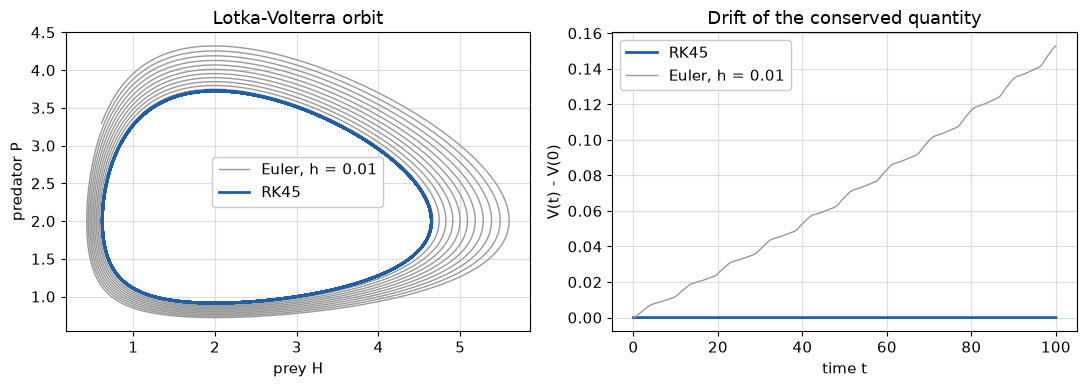

max |V - V0|: RK45 3.7e-10,  Euler 1.5e-01
relative change with 100x tighter tolerances: 8.1e-10
smallest state value at K = 150: 1.109  (> 0)


In [13]:
%%team rishi
fig, check = solver_validation()
plt.show()

pF = with_K(BASE, 150.0)
t = np.linspace(0, 200, 8001)
a = integrate(pF, Y0, (0, 200), t_eval=t).y
b = integrate(pF, Y0, (0, 200), t_eval=t, rtol=1e-12, atol=1e-14).y
print(f"max |V - V0|: RK45 {check['max_drift_rk45']:.1e},  Euler {check['max_drift_euler']:.1e}")
print(f"relative change with 100x tighter tolerances: {np.abs(a - b).max() / np.abs(b).max():.1e}")
print(f"smallest state value at K = 150: {a.min():.3f}  (> 0)")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 1</b>

RK45 keeps $V$ constant to about $10^{-10}$, so its orbit is closed as the theory requires. Euler's $V$ creeps up and its orbit
spirals outward, **inventing** behaviour the model does not have. Without an accurate solver we could not tell a real limit
cycle from a numerical artefact.

</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Step 2 &mdash; Reproducing Section 2's validation targets</b>

For each regime: eigenvalues of the Jacobian (at $E_1 = (K,0)$ for A, where $E^*$ is infeasible; at $E^*$ otherwise), then a
simulation from $(20,5)$ with a 3000-year burn-in and 400 recorded years.

</div>

In [14]:
%%team rishi
rows = regime_table(BASE)
pd.DataFrame([{
    "regime": r["label"], "K": r["K"], "class": r["regime"],
    "eigenvalues": ", ".join(f"{z.real:+.3f}{z.imag:+.3f}i" for z in r["eig"]),
    "H range": f"[{r['Hmin']:.1f}, {r['Hmax']:.1f}]", "P range": f"[{r['Pmin']:.2f}, {r['Pmax']:.2f}]",
    "period (yr)": round(r["period"], 2), "lynx lag (yr)": round(r["lag"], 2)} for r in rows]).set_index("regime")

,K,class,eigenvalues,H range,P range,period (yr),lynx lag (yr)
regime,,,,,,,
A,25.0,predator_extinct,"-1.500+0.000i, -0.073+0.000i","[25.0, 25.0]","[0.00, 0.00]",NaN,NaN
B,60.0,stable_coexistence,"-0.188+0.515i, -0.188-0.515i","[30.0, 30.0]","[11.25, 11.25]",NaN,NaN
C,85.0,stable_coexistence,"-0.022+0.623i, -0.022-0.623i","[30.0, 30.0]","[14.56, 14.56]",NaN,NaN
D,90.0,hopf_point,"+0.000+0.632i, +0.000-0.632i","[28.5, 31.6]","[14.51, 15.49]",9.94,2.50
E,95.0,limit_cycle,"+0.020+0.640i, +0.020-0.640i","[15.8, 50.9]","[9.81, 20.75]",10.25,2.81
F,150.0,limit_cycle,"+0.150+0.676i, +0.150-0.676i","[1.1, 134.3]","[1.69, 41.16]",13.91,4.52


<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading the regime table</b>

Every row reproduces Joel's Table 2: A $\to (25,0)$; B and C settle on $(30, 11.25)$ and $(30, 14.56)$; E has
$H\in[15.8, 50.9]$, $T = 10.25$ yr; F has $H \in [1.1, 134.3]$, $T = 13.91$ yr. At **D** ($K = K_H$) a residual oscillation
of about $\pm 1.5$ remains after 3000 years: at the Hopf point decay is only algebraic ($\sim t^{-1/2}$), so this is a slow
transient, **not** a cycle. The lynx lag grows from about a quarter-period (2.5 yr) at onset to 4.5 yr at $K = 150$.

</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Step 3 &mdash; Time series and phase portraits (Figure 2)</b>

Regimes **B** (well below $K_H$), **C** (just below), **E** (just above), **F** (well above). Prey nullcline: the hump
$P = \frac{r}{a}(1-\frac{H}{K})(b+H)$ with peak at $H = \frac{K-b}{2}$; predator nullcline: the line $H = H^* = 30$.
Graphical criterion: $E^*$ is stable iff the vertical line meets the hump **right of its peak**.

</div>

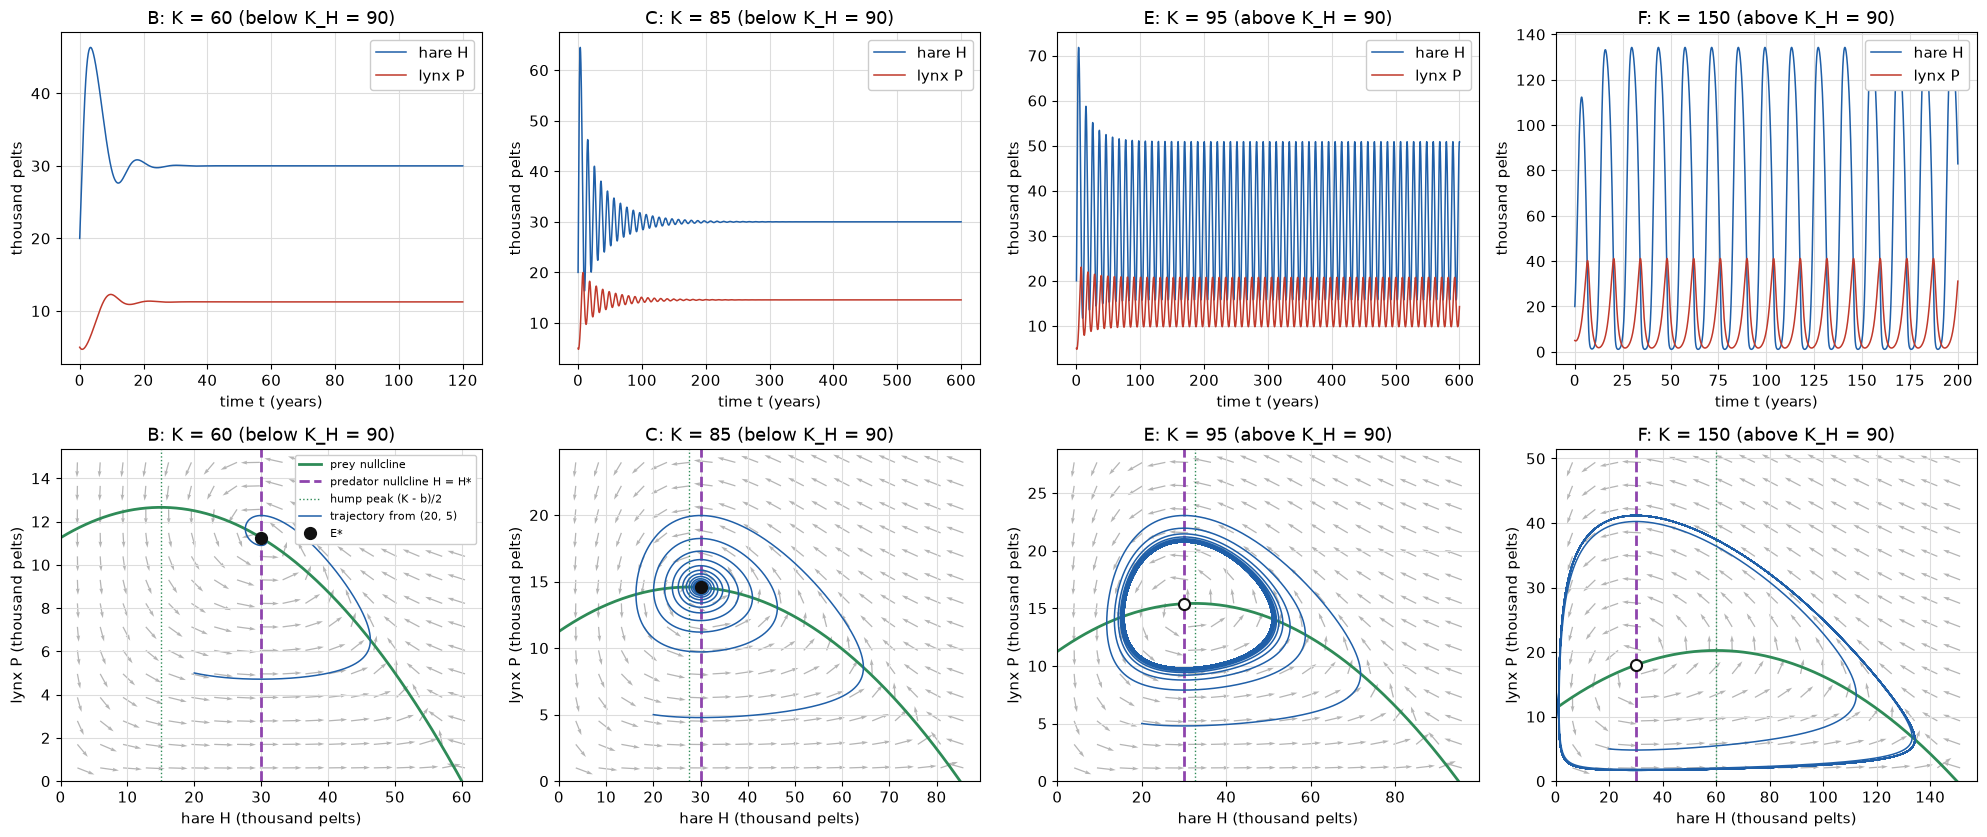

K =  60: trace = -0.3750, det = 0.3000  ->  stable_coexistence
K =  85: trace = -0.0441, det = 0.3882  ->  stable_coexistence
K =  95: trace = +0.0395, det = 0.4105  ->  limit_cycle
K = 150: trace = +0.3000, det = 0.4800  ->  limit_cycle


In [15]:
%%team rishi
fig = regimes(BASE)
plt.show()
for K in (60, 85, 95, 150):
    p = with_K(BASE, K)
    tr, det = st.coexistence_trace_det(p)
    print(f"K = {K:3d}: trace = {tr:+.4f}, det = {det:.4f}  ->  {st.regime(p)}")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 2</b>

- **B ($K=60$):** line right of the peak; oscillations die within a few decades and the orbit spirals into $E^*$.
- **C ($K=85$):** still right of the peak but barely; the trace is only $-0.044$, so decay takes centuries (e-fold about 45 yr).
- **E ($K=95$):** line just left of the peak; $E^*$ is unstable and the orbit settles on a cycle of period about 10 years.
- **F ($K=150$):** a large cycle; hares boom to 134 thousand and crash to about 1 thousand, lynx follow 4.5 years later.

The switch from decay to sustained cycling happens at $K_H = 90$, as Section 2 predicts. The flow is counter-clockwise.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 4 &mdash; Is the cycle a stable limit cycle? (Figure 3)</b>

Lotka&ndash;Volterra has a different closed orbit for every start (neutral stability). A **stable limit cycle** is an isolated
orbit approached from both sides. At $K = 150$ we start inside (next to the unstable $E^*$) and outside, and track hare peaks.

</div>

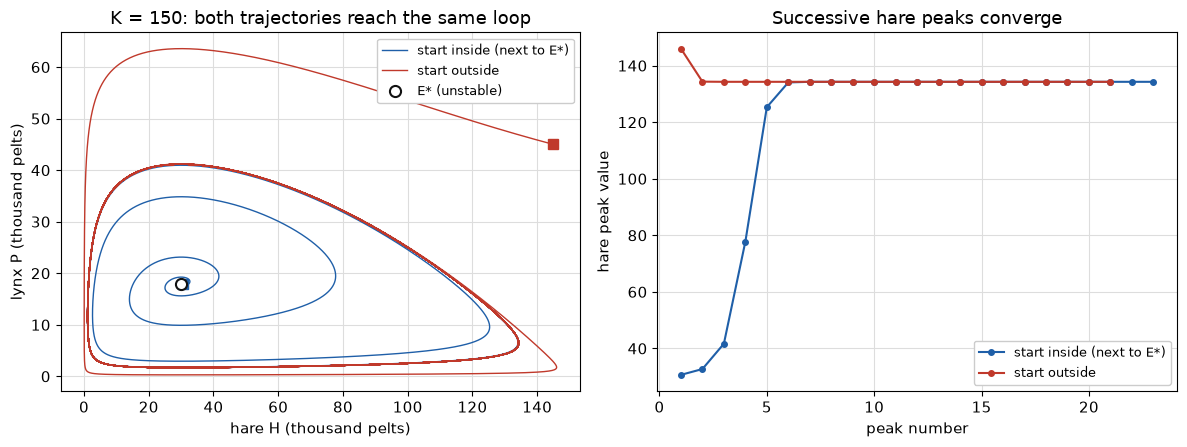

start inside (next to E*)    last three hare peaks: [134.277 134.277 134.277]
start outside                last three hare peaks: [134.277 134.277 134.277]


In [16]:
%%team rishi
fig, last = limit_cycle_attracts(BASE)
plt.show()
for name, peaks in last.items():
    print(f"{name:28s} last three hare peaks: {np.round(peaks, 4)}")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 3</b>

The inside orbit spirals **out**, the outside one spirals **in**, and both peak sequences converge to the same value (134.277).
So after a disturbance the populations return to the *same* cycle, the key improvement over Lotka&ndash;Volterra.
This is numerical evidence for one parameter set; the general statement is Cheng's uniqueness theorem cited in Section 2.

</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Step 5 &mdash; Eigenvalues of J(E*) versus K (Figure 4)</b>

$\det J^* > 0$ for every feasible $K$, so the real part of the eigenvalues has the sign of the trace. Prediction: it changes sign
at exactly $K_H = 90$ with $|\operatorname{Im}\lambda| = \omega_0 \approx 0.632$; below $K \approx 42.5$ the eigenvalues are real (node).

</div>

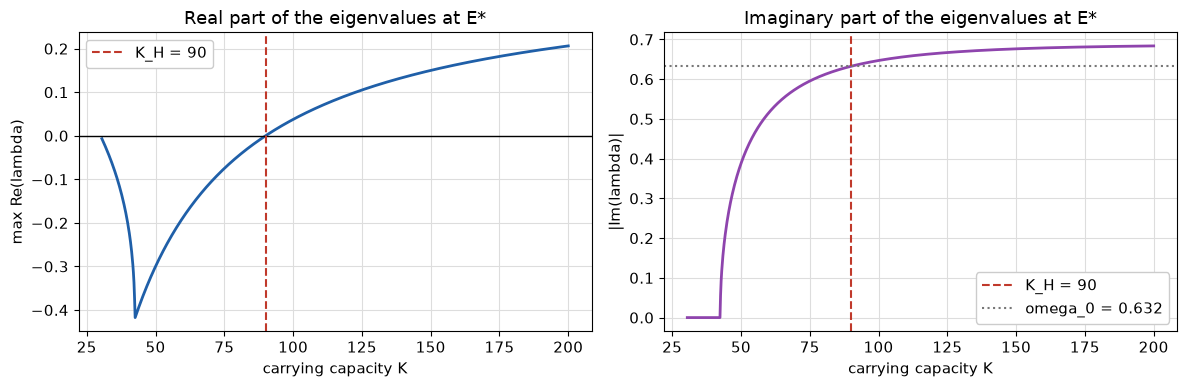

numerical trace zero: K = 90.0000000000   closed form K_H = 90.0000000000
node -> focus at K = 42.6


In [17]:
%%team rishi
fig, info = eigenvalues_vs_K(BASE, np.linspace(30.5, 200, 800))
plt.show()
print(f"numerical trace zero: K = {hopf_crossing(BASE, 60, 120):.10f}   closed form K_H = {KH:.10f}")
print(f"node -> focus at K = {info['node_to_focus_K']:.1f}")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 4</b>

$\operatorname{Re}\lambda$ is negative below 90, zero at 90 and positive above, crossing with nonzero slope (transversality);
$|\operatorname{Im}\lambda| = \omega_0$ at the crossing, so a **complex pair** crosses the imaginary axis: the Hopf condition.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 6 &mdash; Numerical bifurcation diagram (Figure 5)</b>

**Algorithm:** for each $K$ on a grid from 32 to 200, start at $(20,5)$, integrate past the burn-in, **discard** the transient,
and record $\max$ and $\min$ of $H$ and $P$ over 300 further years. Equal max and min: an equilibrium. A gap: a cycle.

</div>

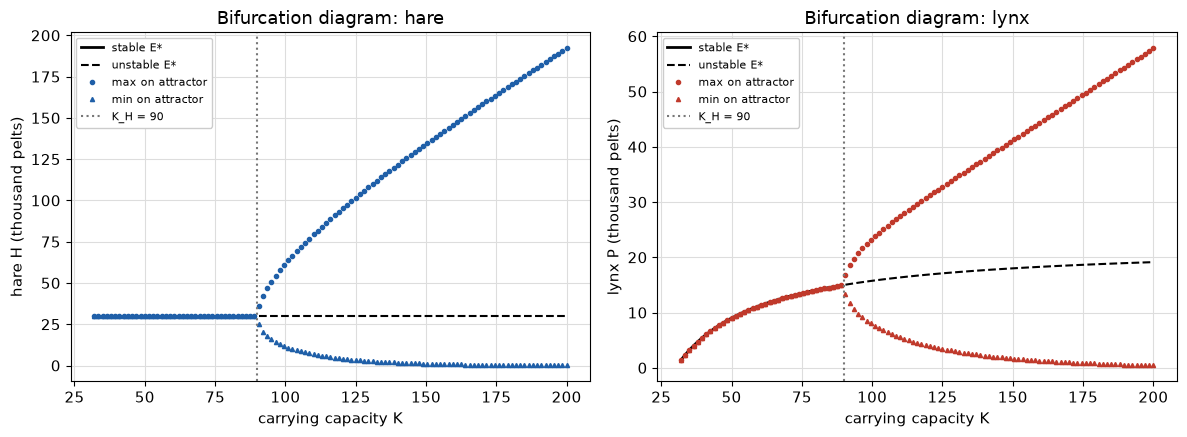

largest max-min of H for K < 89: 4.8e-05
cycle minimum at K = 200: H = 0.115, P = 0.454


In [18]:
%%team rishi
sw = CONFIG["bifurcation_sweep"]
sweep = bifurcation_sweep(BASE, np.linspace(sw["K_min"], sw["K_max"], sw["points"]), t_record=sw["record_years"])
fig = bifurcation(BASE, sweep)
plt.show()
below = sweep["K"] < KH - 1
print(f"largest max-min of H for K < 89: {np.max(sweep['Hmax'][below] - sweep['Hmin'][below]):.1e}")
print(f"cycle minimum at K = 200: H = {sweep['Hmin'][-1]:.3f}, P = {sweep['Pmin'][-1]:.3f}")

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 7 &mdash; Amplitude law and period (Figure 6)</b>

A **supercritical** Hopf bifurcation predicts a cycle born with zero size whose half-amplitude grows like
$A \approx c\sqrt{K-K_H}$ (slope $\tfrac12$ on a log&ndash;log plot; Section 2: $c \approx 7.8$), and whose period tends to
$T_0 = 2\pi/\omega_0$ as $K \to K_H^+$. A subcritical one would instead jump to a large cycle.

</div>

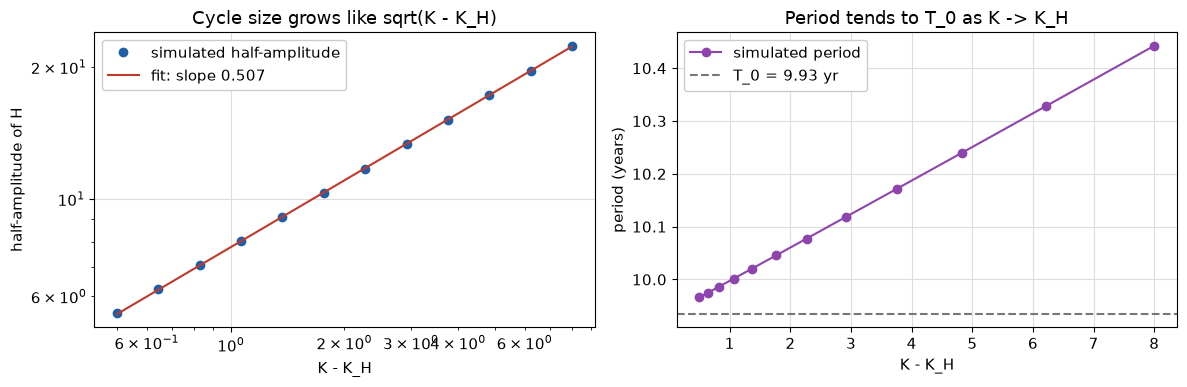

log-log slope s = 0.507  (prediction 0.5)
A = 7.81 * sqrt(K - K_H)  (Section 2: about 7.8)
period at K - K_H = 0.5: 9.966 yr  ->  T_0 = 9.935 yr


In [19]:
%%team rishi
al = CONFIG["amplitude_law"]
law = amplitude_law(BASE, np.geomspace(al["dK_min"], al["dK_max"], al["points"]), t_record=al["record_years"])
fig = amplitude_and_period(law)
plt.show()
print(f"log-log slope s = {law['slope']:.3f}  (prediction 0.5)")
print(f"A = {law['coefficient_sqrt']:.2f} * sqrt(K - K_H)  (Section 2: about 7.8)")
print(f"period at K - K_H = 0.5: {law['period'][0]:.3f} yr  ->  T_0 = {law['onset_period']:.3f} yr")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figures 5 and 6</b>

- **Below $K_H$** max and min coincide on the equilibrium: no cycle.
- **At $K_H$** the branches split and the cycle is born with **zero** size.
- **Above $K_H$** it grows continuously, with slope $\approx 0.507$: the $\sqrt{K-K_H}$ law of a **supercritical** Hopf bifurcation,
  consistent with Joel's computed $\ell_1 < 0$. The period starts at $T_0 \approx 9.94$ yr and lengthens with $K$.
- **Paradox of enrichment:** the minimum branches sink toward zero (hare minimum about 0.1 thousand at $K = 200$).
  The ODE never reaches zero, but a real, finite population at such troughs would risk extinction.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 8 &mdash; Where do the historical fits lie? (Figures 7 and 8)</b>

The fitting sections estimated all six coefficients from the 1900&ndash;1915 pelt indices (thousands of pelts) with a PINN
(13 runs: three error models &times; three seeds, wider bounds, physics weight 100) and matched least squares (18 starts).
For **every** saved parameter set we compute, with Joel's closed forms:

- the stability margin $\sigma = K/K_H$ ($\sigma < 1$: $E^*$ stable, oscillations damp; $\sigma > 1$: limit cycle);
- the eigenvalues $\mu \pm i\omega$ at $E^*$, the **e-folding time** $1/|\mu|$ and the **linear period** $2\pi/\omega$;
- the period and lynx lag of the first century simulated from the fitted 1900 state (Advay's check: about 10 yr, 1&ndash;2 yr);
- which coefficients sit within 0.5% of a box limit.

Only saved parameters and the training file are read; the test file is never opened. First we confirm the parameters are
read correctly: re-integrating Yash's selected fit with `model.solve` and the historical settings must reproduce his saved path.
The bifurcation sweeps take several minutes.

</div>

In [20]:
%%team rishi
if FULL_LONG_RUN_REPLAY:
    import runpy
    placement = runpy.run_path(str(ROOT / "scripts" / "rishi_historical_placement.py"))
    res = placement["compute"]()
    print(f"model.solve reconstruction difference: {res['summary']['reconstruction_max_abs_difference']:.1e}")
    cols = ["label", "sigma", "regime", "eigenvalue", "efold_years", "linear_period",
            "first_century_period", "first_century_lag", "cycle_H_range", "cycle_period", "parameters_on_bounds"]
    display(pd.DataFrame([r for r in res["table"] if r["selected"]])[cols].set_index("label"))
    for k, (lo, hi) in res["summary"]["sigma_range_by_group_excluding_poor_minima"].items():
        print(f"{k:38s} sigma in [{lo:.3f}, {hi:.3f}]")
else:
    import json
    from lynx_hare import simulation as shared_sim
    from lynx_hare.model import Parameters as SharedParameters
    stored=pd.read_csv(ROOT/"results/simulations/historical/fits.csv")
    display(stored)
    summary=json.loads((ROOT/"results/simulations/historical/summary.json").read_text())
    print("Frozen historical long-run summaries:", summary.keys())
    for fitted in json.loads((ROOT/"results/historical/yash_pinn_v1/parameters_for_team.json").read_text()):
        p=SharedParameters(**{k:fitted[k] for k in ["r","K","a","b","e","m"]})
        assert abs(shared_sim.linear_summary(p)["sigma"]-fitted["sigma"])<1e-10
    print("Historical sigma rechecked; set FULL_LONG_RUN_REPLAY=True for expensive long-run regeneration.")

,label,run,selected,poor_local_minimum,r,K,a,b,e,m,...,eigenvalue,efold_years,linear_period,first_century_period,first_century_lag,cycle_H_range,cycle_P_range,cycle_period,parameters_on_bounds,training_mse
0,PINN main,yash_pinn_v1/main_seed17,True,False,0.6055,497.6036,9.2605,299.9760,1.0966,0.9939,...,+0.0079+0.7122i,126.7,8.82,10.70,1.37,"[0.13, 247.1]","[0.00, 212.3]",18.52,K=upper b=upper,NaN
1,PINN main,yash_pinn_v1/main_seed29,False,False,0.6054,496.3888,9.2508,299.9428,1.0979,0.9943,...,+0.0078+0.7123i,127.5,8.82,10.69,1.37,NaN,NaN,NaN,b=upper,NaN
2,PINN main,yash_pinn_v1/main_seed43,False,False,0.6038,498.7204,9.2403,299.9951,1.1016,0.9970,...,+0.0079+0.7124i,126.3,8.82,10.70,1.37,NaN,NaN,NaN,K=upper b=upper,NaN
3,PINN log errors,yash_pinn_v1/log_errors_seed17,False,False,0.5693,482.2315,8.0999,285.7523,1.4087,1.2511,...,+0.0082+0.7667i,122.5,8.20,9.95,1.28,NaN,NaN,NaN,NaN,NaN
4,PINN log errors,yash_pinn_v1/log_errors_seed29,True,False,0.5677,480.2081,8.1092,287.3223,1.4168,1.2536,...,+0.0079+0.7665i,126.6,8.20,9.91,1.29,"[0.27, 240.1]","[0.00, 242.4]",17.37,NaN,NaN
5,PINN log errors,yash_pinn_v1/log_errors_seed43,False,False,0.5662,491.3753,8.3018,295.4531,1.4129,1.2485,...,+0.0077+0.7657i,129.9,8.21,9.90,1.29,NaN,NaN,NaN,NaN,NaN
6,PINN fitted initial state,yash_pinn_v1/fitted_initial_seed17,True,False,0.5370,494.3315,8.4267,299.7805,1.2777,1.0866,...,+0.0070+0.6992i,143.4,8.99,10.71,1.42,"[0.18, 243.4]","[0.00, 230.1]",19.37,b=upper,NaN
7,PINN fitted initial state,yash_pinn_v1/fitted_initial_seed29,False,False,0.5382,494.7524,8.4260,299.7962,1.2747,1.0839,...,+0.0070+0.6991i,142.7,8.99,10.81,1.42,NaN,NaN,NaN,b=upper,NaN
8,PINN fitted initial state,yash_pinn_v1/fitted_initial_seed43,False,False,0.5342,484.5244,8.3753,299.0497,1.2922,1.0944,...,+0.0066+0.6993i,151.8,8.99,10.73,1.42,NaN,NaN,NaN,b=upper,NaN
9,"PINN main, wider bounds",yash_pinn_wider_v1/main_seed17,True,False,0.5737,986.3581,17.1968,599.8807,1.0587,0.9572,...,+0.0049+0.7090i,204.4,8.86,10.49,1.34,"[0.00, 514.7]","[0.00, 472.0]",33.29,b=upper,NaN


Frozen historical long-run summaries: dict_keys(['inputs', 'test_file_opened', 'reconstruction_max_abs_difference', 'sigma_range_by_group_excluding_poor_minima', 'selected', 'training_hare_range'])
Historical sigma rechecked; set FULL_LONG_RUN_REPLAY=True for expensive long-run regeneration.


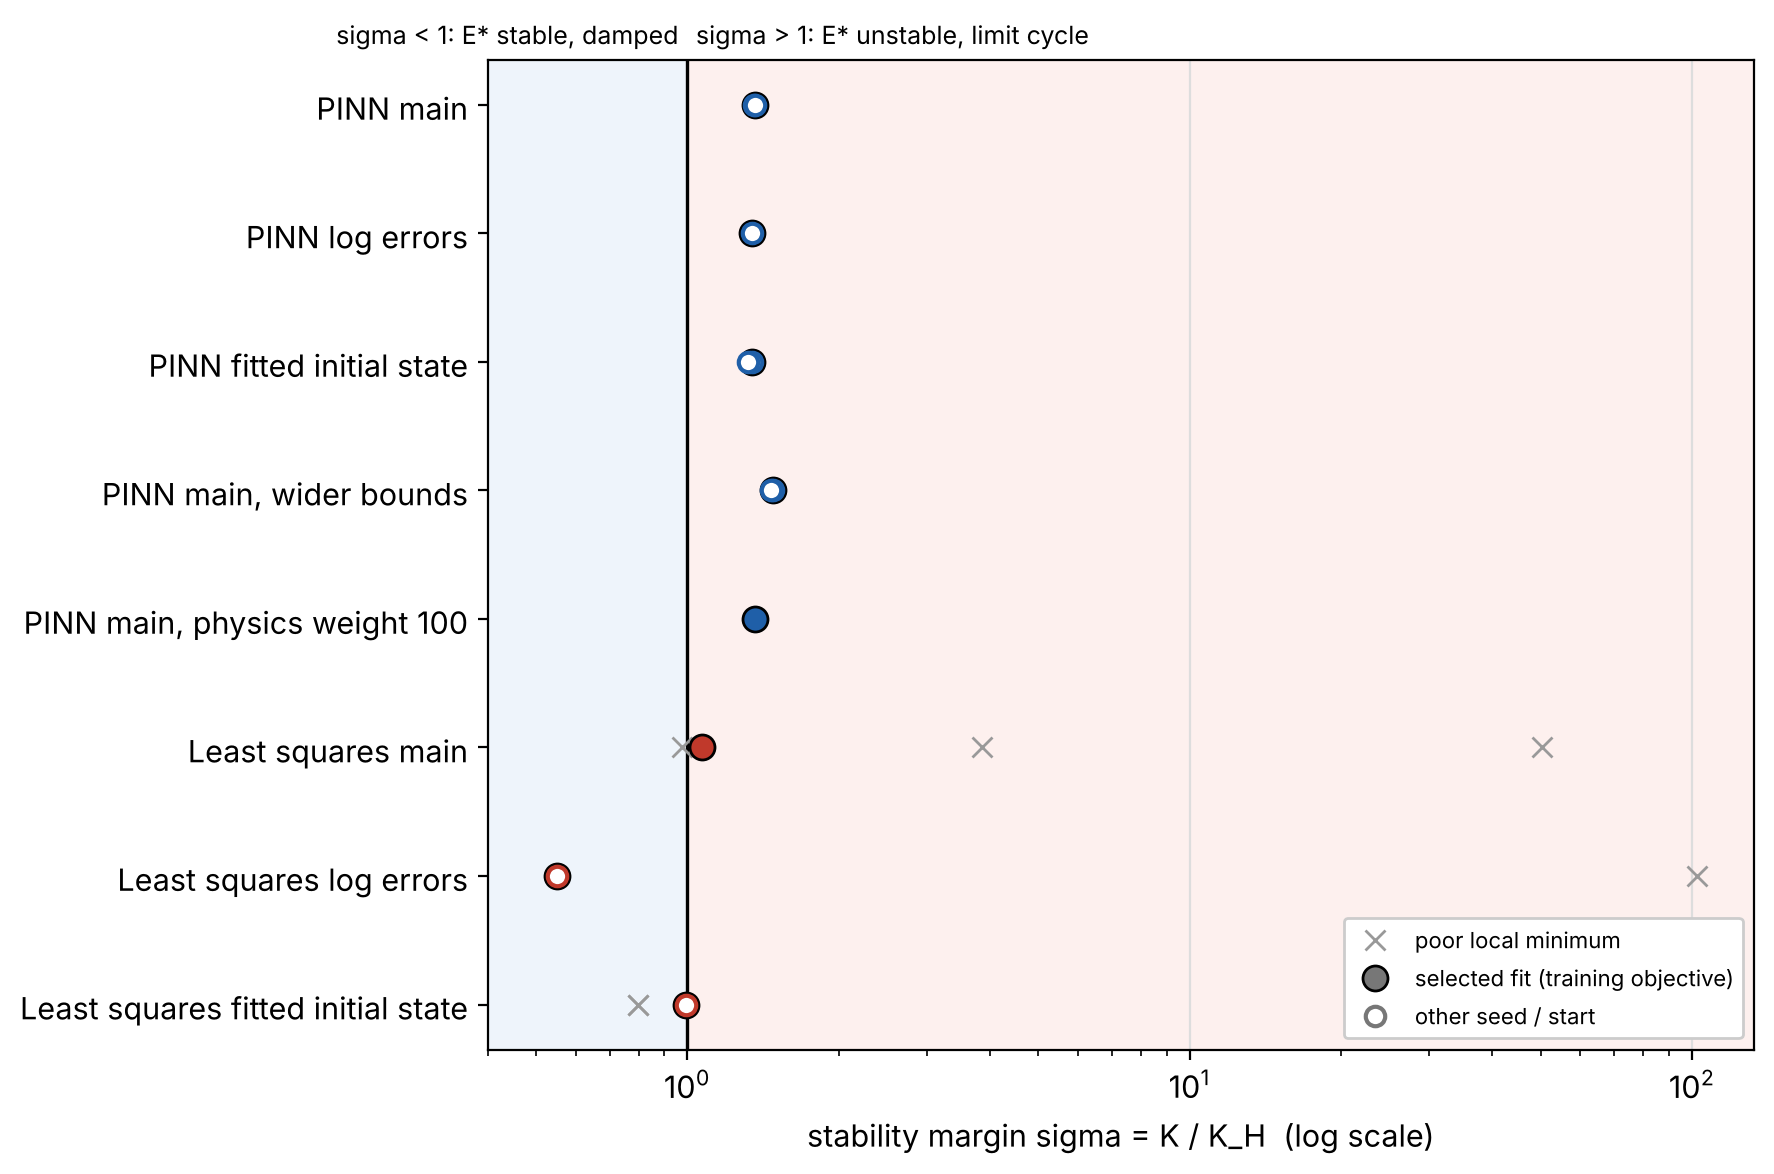

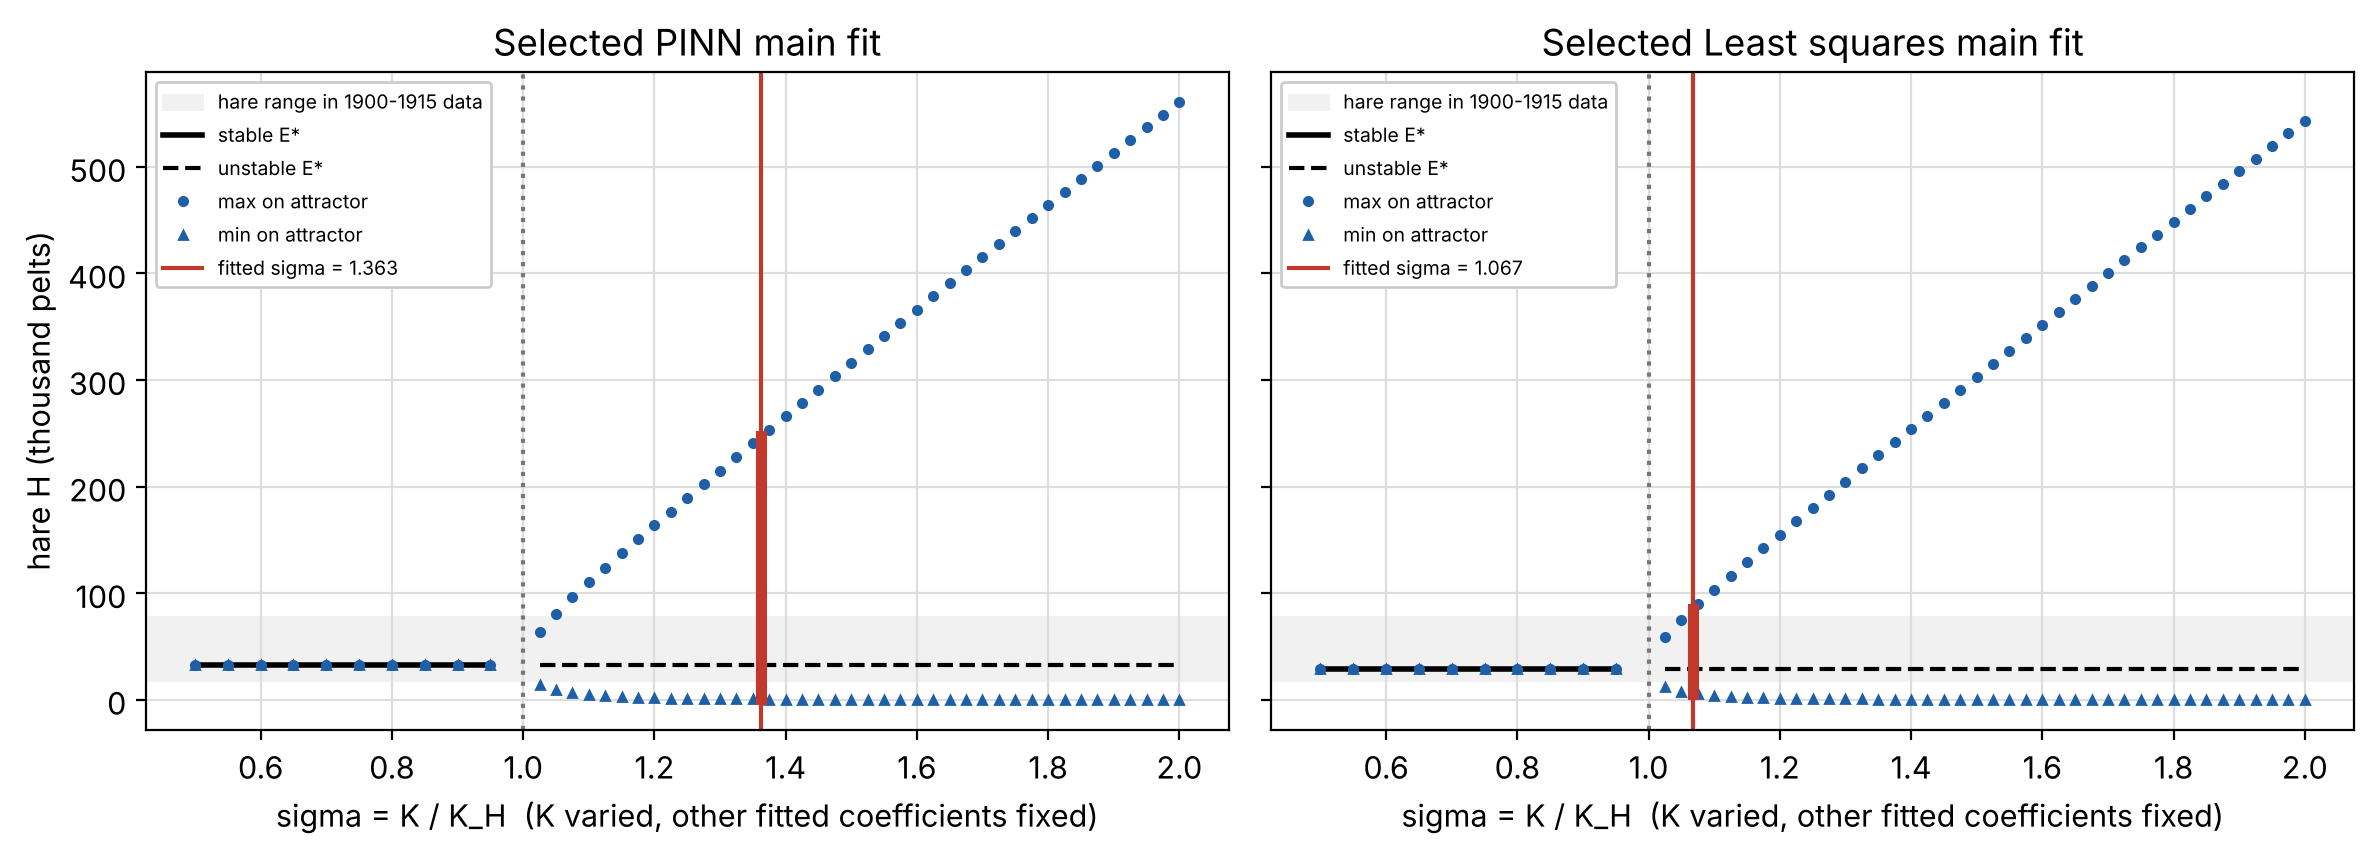

In [21]:
%%team rishi
if FULL_LONG_RUN_REPLAY:
    fig_sigma, fig_bif = placement["figures"](res)
    display(fig_sigma, fig_bif)
    plt.close("all")
else:
    from IPython.display import Image
    for stem in ["rishi_historical_sigma","rishi_historical_bifurcation"]:
        display(Image(filename=str(ROOT/"results/simulations/historical/figures"/(stem+".png"))))

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figures 7 and 8</b>

- **Same behaviour over the data window.** Every well-fitting set oscillates with a period of about 10 years and a lynx lag of
  1.3&ndash;2 years, matching the data.
- **Different side of the threshold.** PINN fits give $\sigma \approx 1.32$&ndash;$1.48$; least squares gives 1.07 (main),
  0.99 (fitted initial state) and 0.55 (log errors).
- **Why the data cannot decide.** $|\mu|$ is only 0.0002&ndash;0.019 per year, so the e-folding time is 53&ndash;5600 years.
  Over 16 training years oscillations change by a factor $e^{16\mu} \approx 0.74$&ndash;$1.16$: a slowly damped focus and a slowly
  growing spiral give almost the same two cycles.
- **Bounds matter.** $b$ sits on its upper limit in nearly every fit; widening the box moves the PINN's $\sigma$ from 1.36 to 1.48.
- **Long run (Figure 8).** The least-squares fit's eventual cycle ($H$ 5.6&ndash;85, period 10.8 yr) resembles the data; the PINN
  fit's is much larger ($H$ 0.1&ndash;247, period 18.5 yr), so its 1900&ndash;1920 trajectory is an early part of a slowly growing spiral.

**Conclusion:** the fitted model sits close to the Hopf threshold and reproduces the observed period and lag, but these data do
not establish whether the real system is on a stable limit cycle or a slowly damped oscillation.

</div>

<div style="background:#f2ecfa; border-left:6px solid #6a3ea1; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#6a3ea1; font-size:1.1em;">Summary and handoff</b>

| Claim | Numerical evidence | Where |
|---|---|---|
| Solver accurate | LV invariant kept to $10^{-10}$ (Euler drifts 0.15); tolerance change $10^{-9}$; positivity | Fig. 1 |
| Section 2 targets | All six regimes, eigenvalues, periods and lags reproduced | table |
| Stability switch at $K_H$ | Decay at $K = 60, 85$; cycles at $K = 95, 150$ | Fig. 2 |
| Stable limit cycle | Inside and outside starts reach the same loop | Fig. 3 |
| Hopf at $K_H = b + 2H^*$ | Trace zero at $K = 90.0000000000$, $|\operatorname{Im}\lambda| = \omega_0$ | Fig. 4 |
| Supercritical Hopf; enrichment | Amplitude $\propto (K-K_H)^{0.507}$, period $\to T_0$, troughs $\to 0$ | Figs. 5, 6 |
| Historical fits | Period ~10 yr, lag 1.3&ndash;2 yr for every good fit; $\sigma$ 0.55&ndash;1.48 depending on method, error model and bounds | Figs. 7, 8 |

**Solvers:** fitting and 1900&ndash;1920 forecasts use `model.solve` (rtol 1e-8, atol 1e-10, max_step 0.1); long-run runs here use
`simulation.integrate` (rtol 1e-10, atol 1e-12).

**Limitations:** the illustrative runs use unfitted parameters; simulation is evidence, not proof; near $K_H$ results depend on
burn-in length; fitted $\sigma$ depends on the box bounds and the error model.

</div>

---
## Yash: credited contribution
Canonical notebook: `notebooks/yash_historical_pinn.ipynb`. Cells below execute in the `yash` namespace.

# Yash: historical inverse PINN study
Real Hudson's Bay Company pelt indices from Advay's Stan compilation, **not synthetic data**.
Training: 1900-1915. Frozen evaluation: 1916-1920. Counts are thousands of pelts, not animal censuses.

This notebook includes the complete model and inverse-PINN training implementations, explains the protocol,
and independently reconstructs the saved forecasts. Default execution audits and displays completed runs;
it does **not** pretend to retrain them. Reproduction commands below create new output directories.
The old synthetic notebook remains the separate controlled recovery study.

In [22]:
%%team yash
import sys, json, hashlib, csv
from pathlib import Path
import numpy as np
import torch
from IPython.display import display, Image, HTML
from html import escape
def show_table(rows):
    names=list(rows[0])
    header='<tr>'+''.join('<th>'+escape(str(n))+'</th>' for n in names)+'</tr>'
    body=''.join('<tr>'+''.join('<td>'+escape(str(row[n]))+'</td>' for n in names)+'</tr>' for row in rows)
    display(HTML('<table>'+header+body+'</table>'))
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src/lynx_hare/model.py').exists(), 'Run in the repository root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
BASE = ROOT / 'results/historical'
config = json.loads((ROOT / 'configs/historical.json').read_text())
show_table([{'parameter':n,'initial_guess':config['initial_guess'][n],'bounds':config['bounds'][n]} for n in config['initial_guess']])

parameter,initial_guess,bounds
r,0.8,"[0.05, 3.0]"
K,150.0,"[20.0, 500.0]"
a,2.0,"[0.05, 10.0]"
b,30.0,"[0.5, 300.0]"
e,0.6,"[0.02, 5.0]"
m,0.6,"[0.05, 3.0]"


## Complete scientific implementation
The following executable cells mirror the canonical modules. Relative imports are rewritten to their
package names so the cells run in Jupyter. The packaged modules and runner remain the canonical route
for batch reproduction; all source hashes are recorded in the notebook metadata and run manifests.

The model uses logistic hare growth and Holling-II predation. The data contract validates positive,
ordered observations and computes scales from training rows only. Positive states, bounded parameters,
automatic-differentiation residuals, deterministic Adam/L-BFGS training and optional fitted initial
states are implemented below. No generating truth enters historical fitting.

In [23]:
%%team yash
# Complete implementation: src/lynx_hare/model.py
"""Shared dimensional model and RK45 solver, provisional until team agreement."""
from dataclasses import dataclass, asdict
import numpy as np
from scipy.integrate import solve_ivp

NAMES = ("r", "K", "a", "b", "e", "m")


@dataclass(frozen=True)
class Parameters:
    r: float
    K: float
    a: float
    b: float
    e: float
    m: float

    def __post_init__(self):
        if not all(np.isfinite(v) and v > 0 for v in asdict(self).values()):
            raise ValueError("Every model parameter must be finite and positive")

    def to_dict(self):
        return asdict(self)


def rhs(t, state, p):
    """H' = rH(1-H/K)-aHP/(b+H); P' = eaHP/(b+H)-mP."""
    H, P = state
    consumption = p.a * H * P / (p.b + H)
    return np.array([p.r * H * (1 - H / p.K) - consumption,
                     p.e * consumption - p.m * P])


def rhs_torch(state, p):
    """Same equations, batch shape (N, 2), preserving the autograd graph."""
    import torch
    H, P = state[:, :1], state[:, 1:]
    consumption = p["a"] * H * P / (p["b"] + H)
    return torch.cat((p["r"] * H * (1 - H / p["K"]) - consumption,
                      p["e"] * consumption - p["m"] * P), dim=1)


def solve(times, initial_state, p, rtol=1e-8, atol=1e-10, max_step=0.1):
    """State at strictly increasing times; initial_state belongs to times[0]."""
    times = np.asarray(times, dtype=float)
    y0 = np.asarray(initial_state, dtype=float)
    if times.ndim != 1 or times.size == 0 or not np.isfinite(times).all():
        raise ValueError("times must be a nonempty finite 1D array")
    if np.any(np.diff(times) <= 0) or y0.shape != (2,) or not np.isfinite(y0).all() or np.any(y0 < 0):
        raise ValueError("times must increase; initial_state must contain two nonnegative values")
    if times.size == 1:
        return y0[None, :].copy()
    result = solve_ivp(lambda t, y: rhs(t, y, p), (times[0], times[-1]), y0,
                       t_eval=times, method="RK45", rtol=rtol, atol=atol, max_step=max_step)
    if not result.success or result.y.shape[1] != len(times):
        raise RuntimeError(f"ODE integration failed: {result.message}")
    states = result.y.T
    if not np.isfinite(states).all() or np.min(states) < -100 * atol:
        raise RuntimeError("ODE returned invalid or negative states")
    return states

In [24]:
%%team yash
# Complete implementation: src/lynx_hare/data.py
"""Validated training contract and independently generated synthetic observations."""
from dataclasses import dataclass
from pathlib import Path
import csv
import numpy as np
from lynx_hare.model import Parameters, solve


@dataclass
class TrainingData:
    years: np.ndarray
    observations: np.ndarray
    time_origin: float

    def __post_init__(self):
        self.years = np.asarray(self.years, dtype=float)
        self.observations = np.asarray(self.observations, dtype=float)
        if (self.years.ndim != 1 or len(self.years) < 2
                or self.observations.shape != (len(self.years), 2)
                or not np.isfinite(self.years).all()
                or not np.isfinite(self.observations).all()
                or np.any(np.diff(self.years) <= 0)
                or np.any(self.observations <= 0)
                or not np.isfinite(self.time_origin)
                or self.years[0] != self.time_origin):
            raise ValueError("Training data require increasing years and positive finite Hare/Lynx observations, starting at time_origin")

    @property
    def times(self):
        return self.years - self.time_origin

    @property
    def scale(self):
        # This method has no access to test observations or generating parameters.
        return self.observations.max(axis=0)

    @property
    def initial_state(self):
        return self.observations[0].copy()


def write_csv(path, columns, values):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(columns)
        writer.writerows(values)


def read_training(path, time_origin=1900, train_end=1915):
    with Path(path).open(newline="", encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f))
    values = np.array([[float(r[k]) for k in ("Year", "Hare", "Lynx")] for r in rows])
    values = values[values[:, 0] <= train_end]
    return TrainingData(values[:, 0], values[:, 1:], time_origin)


def synthetic(config, times, noise_fraction=None, seed=None):
    """Noise is multiplicative Gaussian with exact controlled initial condition.

    In this synthetic experiment the initial state is treated as measured exactly.
    This is an explicit experimental assumption, not a claim about pelt data.
    """
    noise = config["noise_fraction"] if noise_fraction is None else noise_fraction
    if noise < 0:
        raise ValueError("noise_fraction cannot be negative")
    states = solve(times, config["initial_state"], Parameters(**config["truth"]), **config["solver"])
    rng = np.random.default_rng(config["data_seed"] if seed is None else seed)
    observed = states * (1 + noise * rng.normal(size=states.shape))
    observed = np.maximum(observed, 1e-8)
    observed[0] = states[0]
    return states, observed

In [25]:
%%team yash
# Complete implementation: src/lynx_hare/pinn.py
"""Inverse PINN trained only on a TrainingData object and fixed configuration."""
import copy
import random
import time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from lynx_hare.model import NAMES, Parameters, rhs_torch

DTYPE = torch.float64


class InversePINN(nn.Module):
    def __init__(self, duration, scale, guess, bounds, trainable, width=48, depth=3):
        super().__init__()
        if duration <= 0 or not set(trainable).issubset(NAMES) or len(set(trainable)) != len(trainable):
            raise ValueError("Invalid duration or trainable parameter names")
        self.duration = float(duration)
        self.register_buffer("scale", torch.as_tensor(scale, dtype=DTYPE))
        self.fixed = {k: float(v) for k, v in guess.items() if k not in trainable}
        self.bounds = bounds
        self.raw = nn.ParameterDict()
        for k in trainable:
            lo, hi = bounds[k]
            if not 0 < lo < guess[k] < hi:
                raise ValueError(f"Initial guess for {k} must lie strictly within positive bounds")
            q = (guess[k] - lo) / (hi - lo)
            self.raw[k] = nn.Parameter(torch.tensor(np.log(q / (1 - q)), dtype=DTYPE))
        layers = [nn.Linear(1, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers.extend((nn.Linear(width, width), nn.Tanh()))
        layers.append(nn.Linear(width, 2))
        self.network = nn.Sequential(*layers).to(dtype=DTYPE)
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def parameter_values(self):
        values = dict(self.fixed)
        for k, raw in self.raw.items():
            lo, hi = self.bounds[k]
            values[k] = lo + (hi - lo) * torch.sigmoid(raw)
        return values

    def inferred(self):
        return Parameters(**{k: float(v.detach()) if isinstance(v, torch.Tensor) else float(v)
                             for k, v in self.parameter_values().items()})

    def forward(self, times):
        # The network is defined on scaled time [-1, 1]. Output positivity is strict.
        return F.softplus(self.network(2 * times / self.duration - 1)) + 1e-10

    def residuals(self, times):
        times = times.detach().clone().requires_grad_(True)
        normalized = self(times)
        derivatives = torch.cat([
            torch.autograd.grad(normalized[:, j:j+1], times,
                                torch.ones_like(normalized[:, j:j+1]), create_graph=True)[0]
            for j in range(2)], dim=1)
        return derivatives - rhs_torch(normalized * self.scale, self.parameter_values()) / self.scale


def loss_parts(model, times, observations, collocation, initial):
    data = ((model(times) - observations / model.scale) ** 2).mean()
    residual = model.residuals(collocation)
    physics_hare = residual[:, 0].square().mean()
    physics_lynx = residual[:, 1].square().mean()
    ic = ((model(torch.zeros((1, 1), dtype=DTYPE)) - initial / model.scale) ** 2).mean()
    return {"data": data, "physics": (physics_hare + physics_lynx) / 2,
            "physics_hare": physics_hare, "physics_lynx": physics_lynx, "ic": ic}


def fit_pinn(data, config, seed, training_overrides=None, initial_factor=1.0, trainable=None):
    """No truth, held-out observations, or held-out metrics enter optimization."""
    settings = {**config["training"], **(training_overrides or {})}
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(settings["threads"])
    torch.use_deterministic_algorithms(True)
    names = config["trainable"] if trainable is None else trainable
    guess = dict(config["initial_guess"])
    for k in names:
        lo, hi = config["bounds"][k]
        guess[k] = float(np.clip(guess[k] * initial_factor, lo + 1e-4, hi - 1e-4))
    model = InversePINN(data.times[-1], data.scale, guess, config["bounds"], names,
                        settings["width"], settings["depth"])
    times = torch.as_tensor(data.times[:, None], dtype=DTYPE)
    observed = torch.as_tensor(data.observations, dtype=DTYPE)
    initial = torch.as_tensor(data.initial_state, dtype=DTYPE)
    collocation = torch.linspace(0, data.times[-1], settings["collocation_points"], dtype=DTYPE)[:, None]
    history, best_state = [], None
    best_loss, stale, best_iteration = float("inf"), 0, -1
    start = time.perf_counter()

    def total(parts):
        return (settings["data_weight"] * parts["data"] + settings["physics_weight"] * parts["physics"]
                + settings["ic_weight"] * parts["ic"])

    def record(stage, step):
        nonlocal best_state, best_loss, stale, best_iteration
        parts = loss_parts(model, times, observed, collocation, initial)
        score = float(total(parts).detach())
        if not np.isfinite(score):
            raise RuntimeError("Nonfinite PINN training objective")
        history.append({"stage": stage, "step": step, "total": score,
                        **{k: float(v.detach()) for k, v in parts.items()}})
        improved_materially = score < best_loss - settings["min_delta"]
        stale = 0 if improved_materially else stale + 1
        if score < best_loss:
            best_loss, best_state, best_iteration = score, copy.deepcopy(model.state_dict()), step
        return score

    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
    # Warmup fits states before physics is introduced. No parameters are inferred in warmup.
    for _ in range(settings["warmup_steps"]):
        optimizer.zero_grad()
        warm = ((model(times) - observed / model.scale) ** 2).mean()
        warm = warm + settings["ic_weight"] * ((model(times[:1]) - initial / model.scale) ** 2).mean()
        warm.backward()
        optimizer.step()
    record("joint_adam", 0)
    adam_stop = "maximum_steps"
    for step in range(1, settings["adam_steps"] + 1):
        optimizer.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, initial))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite PINN loss")
        objective.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"])
        optimizer.step()
        if step % settings["log_every"] == 0 or step == settings["adam_steps"]:
            record("joint_adam", step)
            if stale >= settings["patience"]:
                adam_stop = "training_plateau"
                break
    model.load_state_dict(best_state)
    closure_evaluations = 0
    optimizer2 = torch.optim.LBFGS(model.parameters(), max_iter=settings["lbfgs_steps"],
                                  line_search_fn="strong_wolfe", tolerance_grad=1e-10,
                                  tolerance_change=1e-12, history_size=50)

    def closure():
        nonlocal closure_evaluations
        optimizer2.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, initial))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite L-BFGS loss")
        objective.backward()
        closure_evaluations += 1
        if closure_evaluations % 25 == 0:
            record("lbfgs", settings["adam_steps"] + closure_evaluations)
        return objective

    if settings["lbfgs_steps"]:
        optimizer2.step(closure)
        record("lbfgs_final", settings["adam_steps"] + closure_evaluations)
    model.load_state_dict(best_state)
    audit = {"seed": seed, "settings": settings, "trainable": names, "initial_guess": guess,
             "fixed": model.fixed, "scale": data.scale.tolist(), "train_years": data.years.tolist(),
             "training_objective": best_loss, "best_iteration": best_iteration,
             "adam_stop": adam_stop, "lbfgs_iterations": optimizer2.state.get(next(iter(model.parameters())), {}).get("n_iter", 0),
             "lbfgs_closure_evaluations": closure_evaluations,
             "elapsed_seconds": time.perf_counter() - start,
             "selection_rule": "minimum weighted training loss; held-out data never used"}
    return model, history, audit

In [26]:
%%team yash
# Complete implementation: src/lynx_hare/historical_pinn.py
"""Historical fitting extensions; synthetic experiment sources remain frozen.

Only a TrainingData object enters optimization. Historical coefficients are effective
coefficients in the observation units, with bounds supplied by the common team config.
"""
import copy
import random
import time

import numpy as np
import torch
from torch import nn

from lynx_hare.model import NAMES
from lynx_hare.pinn import DTYPE, InversePINN


def validate_config(config):
    """Require explicit historical choices instead of borrowing synthetic constants."""
    if config.get("kind") != "historical" or "truth" in config:
        raise ValueError("Provide a historical config without generating truth")
    names = config.get("trainable", [])
    if not names or len(set(names)) != len(names) or not set(names) <= set(NAMES):
        raise ValueError("Declare distinct trainable model parameters")
    guesses, bounds = config.get("initial_guess"), config.get("bounds")
    if not isinstance(guesses, dict) or set(guesses) != set(NAMES):
        raise ValueError("Please supply initial_guess for all six parameters")
    if not isinstance(bounds, dict):
        raise ValueError("Please supply common positive parameter bounds")
    for name in NAMES:
        if not np.isfinite(guesses[name]) or guesses[name] <= 0:
            raise ValueError(f"Invalid initial/fixed value for {name}")
        if name in names:
            lo, hi = bounds[name]
            if not np.isfinite([lo, hi]).all() or not 0 < lo < guesses[name] < hi:
                raise ValueError(f"Require positive bounds containing the guess for {name}")
    if set(config.get("solver", {})) != {"rtol", "atol", "max_step"}:
        raise ValueError("Declare shared rtol, atol and max_step")
    if any(not np.isfinite(v) or v <= 0 for v in config["solver"].values()):
        raise ValueError("Solver settings must be finite and positive")
    for key in ("start_year", "train_end_year", "forecast_end_year", "training", "seeds"):
        if key not in config:
            raise ValueError(f"Missing {key}")
    if not config["start_year"] < config["train_end_year"] < config["forecast_end_year"]:
        raise ValueError("Require training years before forecast years")
    if not config["seeds"] or len(set(config["seeds"])) != len(config["seeds"]):
        raise ValueError("Declare distinct optimization seeds")
    if any(not isinstance(seed, int) or seed < 0 for seed in config["seeds"]):
        raise ValueError("Seeds must be nonnegative integers")
    settings = config["training"]
    for key in ("width", "depth", "collocation_points", "log_every", "patience", "threads"):
        if not isinstance(settings.get(key), int) or settings[key] < 1:
            raise ValueError(f"Require a positive integer {key}")
    if settings["collocation_points"] < 2:
        raise ValueError("Use at least two collocation points")
    for key in ("warmup_steps", "adam_steps", "lbfgs_steps"):
        if not isinstance(settings.get(key), int) or settings[key] < 0:
            raise ValueError(f"Require nonnegative integer {key}")
    for key in ("learning_rate", "data_weight", "physics_weight", "ic_weight", "gradient_clip", "min_delta"):
        value = settings.get(key)
        if value is None or not np.isfinite(value) or value < 0 or (key != "min_delta" and value == 0):
            raise ValueError(f"Invalid {key}")


class HistoricalPINN(InversePINN):
    def __init__(self, data, config, fit_initial=False):
        settings = config["training"]
        super().__init__(data.times[-1], data.scale, config["initial_guess"],
                         config["bounds"], config["trainable"],
                         settings["width"], settings["depth"])
        self.register_buffer("observed_initial", torch.as_tensor(data.initial_state, dtype=DTYPE))
        self.fit_initial = bool(fit_initial)
        if fit_initial:
            # Midpoint of [0.5*y0, 1.5*y0] is the observed initial state.
            self.raw_initial = nn.Parameter(torch.zeros(2, dtype=DTYPE))

    def initial_values(self):
        if self.fit_initial:
            return self.observed_initial * (0.5 + torch.sigmoid(self.raw_initial))
        return self.observed_initial


def observation_loss(predicted, observed, scale, error_model):
    if error_model == "additive":
        return ((predicted - observed) / scale).square().mean()
    if error_model == "log":
        return (torch.log(predicted) - torch.log(observed)).square().mean()
    raise ValueError("error_model must be additive or log")


def loss_parts(model, times, observed, collocation, error_model="additive"):
    data_loss = observation_loss(model(times) * model.scale, observed, model.scale, error_model)
    residual = model.residuals(collocation)
    initial = model.initial_values()
    ic = ((model(times[:1]) - initial / model.scale) ** 2).mean()
    return {"data": data_loss, "physics": residual.square().mean(), "ic": ic,
            "physics_hare": residual[:, 0].square().mean(),
            "physics_lynx": residual[:, 1].square().mean()}


def fit_historical(data, config, seed, error_model="additive", fit_initial=False):
    """Fit a frozen training split; no test path or test observations are accepted."""
    validate_config(config)
    if data.years.tolist() != list(range(config["start_year"], config["train_end_year"] + 1)):
        raise ValueError("TrainingData must contain the complete declared annual training split")
    if error_model not in ("additive", "log"):
        raise ValueError("error_model must be additive or log")
    s = config["training"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(s["threads"])
    torch.use_deterministic_algorithms(True)
    model = HistoricalPINN(data, config, fit_initial)
    times = torch.tensor(data.times[:, None], dtype=DTYPE)
    observed = torch.tensor(data.observations, dtype=DTYPE)
    collocation = torch.linspace(0, data.times[-1], s["collocation_points"], dtype=DTYPE)[:, None]
    start = time.perf_counter()
    history, best_state = [], None
    best_loss, stale, best_iteration = float("inf"), 0, -1

    def total(parts):
        return sum(s[f"{key}_weight"] * parts[key] for key in ("data", "physics", "ic"))

    def record(stage, step):
        nonlocal best_loss, best_state, stale, best_iteration
        parts = loss_parts(model, times, observed, collocation, error_model)
        score = float(total(parts).detach())
        if not np.isfinite(score):
            raise RuntimeError("Nonfinite historical training loss")
        history.append({"stage": stage, "step": step, "total": score,
                        **{k: float(v.detach()) for k, v in parts.items()}})
        stale = 0 if score < best_loss - s["min_delta"] else stale + 1
        if score < best_loss:
            best_loss, best_state, best_iteration = score, copy.deepcopy(model.state_dict()), step
        return score

    optimizer = torch.optim.Adam(model.parameters(), lr=s["learning_rate"])
    for _ in range(s["warmup_steps"]):
        optimizer.zero_grad()
        data_loss = observation_loss(model(times) * model.scale, observed, model.scale, error_model)
        ic = ((model(times[:1]) - model.initial_values() / model.scale) ** 2).mean()
        warmup = s["data_weight"] * data_loss + s["ic_weight"] * ic
        warmup.backward()
        optimizer.step()
    record("joint_adam", 0)
    adam_stop = "maximum_steps"
    for step in range(1, s["adam_steps"] + 1):
        optimizer.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, error_model))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite historical Adam loss")
        objective.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), s["gradient_clip"])
        optimizer.step()
        if step % s["log_every"] == 0 or step == s["adam_steps"]:
            record("joint_adam", step)
            if stale >= s["patience"]:
                adam_stop = "training_plateau"
                break
    model.load_state_dict(best_state)
    closure_evaluations = 0
    lbfgs = torch.optim.LBFGS(model.parameters(), max_iter=s["lbfgs_steps"],
                             line_search_fn="strong_wolfe", tolerance_grad=1e-10,
                             tolerance_change=1e-12, history_size=50)

    def closure():
        nonlocal closure_evaluations
        lbfgs.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, error_model))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite historical L-BFGS loss")
        objective.backward()
        closure_evaluations += 1
        if closure_evaluations % 25 == 0:
            record("lbfgs", s["adam_steps"] + closure_evaluations)
        return objective

    if s["lbfgs_steps"]:
        lbfgs.step(closure)
        record("lbfgs_final", s["adam_steps"] + closure_evaluations)
    model.load_state_dict(best_state)
    with torch.no_grad():
        network_initial = (model(times[:1]) * model.scale).numpy()[0]
        ode_initial = model.initial_values().numpy()
    audit = {"seed": int(seed), "settings": dict(s), "trainable": config["trainable"],
             "fixed": model.fixed, "initial_guess": config["initial_guess"],
             "scale": data.scale.tolist(), "train_years": data.years.tolist(),
             "error_model": error_model, "fit_initial": fit_initial,
             "initial_bounds_factors": [0.5, 1.5] if fit_initial else None,
             "observed_initial": data.initial_state.tolist(), "ode_initial": ode_initial.tolist(),
             "network_initial": network_initial.tolist(),
             "network_minus_ode_initial": (network_initial - ode_initial).tolist(),
             "network_minus_observed_initial": (network_initial - data.initial_state).tolist(),
             "training_objective": best_loss, "best_iteration": best_iteration,
             "adam_stop": adam_stop, "lbfgs_closure_evaluations": closure_evaluations,
             "elapsed_seconds": time.perf_counter() - start,
             "selection_rule": "minimum weighted training loss within each variant; no held-out scores"}
    return model, history, audit

## Frozen data and loss
The primary residual is `(prediction-observation)/training_max`, with one equal contribution per species.
The physics residual differentiates normalized states with respect to physical time, retaining both time
and state scaling. Weights are data=1, physics=10, IC=10. The network has 3 x 48 tanh units; outputs use
softplus and all six parameters use positive sigmoid bounds. The primary ODE initial state is (30,4).
The PINN's initial-state constraint is soft, and its discrepancy is explicitly reported.

Seeds 17,29,43 are selected by weighted **training** loss within each variant. Log errors and fitted
initial states are separate declared sensitivities. Wider bounds and physics weight 100 are retained
as sensitivity results, not promoted after scoring. The local benchmark uses the exact same primary
config; it is an independent check, not a claim that Advay has completed his own fitting task.

In [27]:
%%team yash
from run_historical_pinn import training_split
data, train_path = training_split(ROOT)
validate_config(config)
assert data.years.tolist() == list(range(1900,1916))
show_table([{'species':n,'scale':float(data.scale[i]),'observed_initial':float(data.initial_state[i])} for i,n in enumerate(['Hare','Lynx'])])
from score_historical import frozen
for folder in ['yash_pinn_v1','yash_pinn_wider_v1','yash_pinn_physics100_v1','yash_matching_baseline_v2']:
    assert frozen(BASE/folder)['status'] == 'forecasts_frozen_unscored'
print('All frozen output and scientific-source hashes verified.')

species,scale,observed_initial
Hare,77.4,30.0
Lynx,59.4,4.0


All frozen output and scientific-source hashes verified.


## Independent ODE reconstruction and seed diagnostics
Forecasts use RK45 from 1900 through 1920 with the learned parameters, never neural-network extrapolation.
The code below reconstructs every saved five-year forecast without reading held-out observations.
Local sensitivity condition numbers describe this fitted model only; seed spread is not a confidence interval.

In [28]:
%%team yash
from lynx_hare.model import Parameters as ModelParameters, solve as solve_model
summaries=[]
for dirname in ['yash_pinn_v1','yash_pinn_wider_v1','yash_pinn_physics100_v1']:
    for path in sorted((BASE/dirname/'runs').glob('*/summary.json')):
        s=json.loads(path.read_text())
        predicted=solve_model(np.arange(21), s['audit']['ode_initial'], ModelParameters(**s['parameters']), **config['solver'])
        exported=np.loadtxt(path.parent/'forecast.csv',delimiter=',',skiprows=1)
        np.testing.assert_allclose(predicted[16:],exported[:,1:],rtol=1e-11,atol=1e-11)
        summaries.append({'case':dirname,'run':s['run_id'],**s['parameters'],
                          'sigma':s['diagnostics']['sigma'],'condition':s['diagnostics']['condition_number'],
                          'ODE_training_MSE':s['training_ode_normalized_mse'],
                          'IC_difference':s['audit']['network_minus_observed_initial']})
show_table(summaries)
print('All 13 PINN forecast files independently reconstructed.')

case,run,r,K,a,b,e,m,sigma,condition,ODE_training_MSE,IC_difference
yash_pinn_v1,fitted_initial_seed17,0.5369857392202834,494.3315391000688,8.4267483705291,299.78047611799553,1.2776886710415303,1.0865641827006949,1.3466631084234548,376.32021201792105,0.007397575671543076,"[4.748494882566362, -0.21273733019904562]"
yash_pinn_v1,fitted_initial_seed29,0.5381552010422098,494.75238001877835,8.426021600751403,299.7961783886361,1.2746803572717784,1.083903392139589,1.3477412529835742,378.4647294208746,0.007554467642784173,"[4.776998725351156, -0.1439694727710248]"
yash_pinn_v1,fitted_initial_seed43,0.534185429419636,484.5243524363303,8.37533361295525,299.0496790066312,1.2921963001546541,1.0943713671999775,1.322634777999213,366.5540852873775,0.007108297978537691,"[4.77481864784361, -0.41352318229918517]"
yash_pinn_v1,log_errors_seed17,0.5693255607037517,482.2314889545448,8.099947902699165,285.7523457798198,1.4086939996362906,1.2510623077820082,1.3540878837925454,237.57480586461716,0.03683797954497296,"[0.14308781077327737, 0.03775511719486957]"
yash_pinn_v1,log_errors_seed29,0.5677196050491092,480.208094755309,8.109206367302061,287.32228033361156,1.4167571556077772,1.2536310403118214,1.3424641511292394,238.70758529100775,0.03664816171639651,"[0.14691172120478413, 0.027105604319809906]"
yash_pinn_v1,log_errors_seed43,0.5661685060151416,491.37525627800824,8.301833714423232,295.4530756916458,1.4129289895807018,1.2485027868650747,1.3431444175754768,242.9879566251065,0.03621269717654681,"[0.1458599590206653, 0.03282178237451028]"
yash_pinn_v1,main_seed17,0.6054636470501683,497.6036084434827,9.260547309106517,299.97597885269994,1.0965764328360263,0.9938788576936693,1.3630557174287483,317.4622204217257,0.009814353680621918,"[0.1006049973344254, -0.007232455177729413]"
yash_pinn_v1,main_seed29,0.6053500024895941,496.3887726925364,9.250805360534054,299.9427975014707,1.097921193922284,0.9943007149827313,1.3598108570956315,317.1293144739623,0.00982414706703916,"[0.10036036470651055, -0.006808389810388338]"
yash_pinn_v1,main_seed43,0.6037762601792512,498.720375389894,9.240339855637181,299.99507339569186,1.1016272981598108,0.9970454489674253,1.3658198932860592,318.6781981175164,0.009845020966307724,"[0.09838015703551761, -0.009686621741806345]"
yash_pinn_wider_v1,main_seed17,0.5737460993696418,986.3580878560481,17.196807915747776,599.8806849028679,1.058671770023306,0.9572297740639936,1.479989368056137,593.182639298418,0.009347371363618113,"[0.09810788081879807, -0.006855162558359051]"


All 13 PINN forecast files independently reconstructed.


## Final evaluation and figures
All model choices and forecasts were frozen before evaluation. Scores are RMSE and MAE for each species
in original pelt units, on the same five test years. Primary hare RMSE is slightly better for the PINN,
while primary lynx RMSE is worse. The table contains **all** declared sensitivity outcomes.
No method or variant is selected using this table. Boundary sensitivity prevents claims of uniquely
identified biological coefficients; a fitted sigma above one describes the fitted ODE, not proof of a
real ecological limit cycle. The report discusses the small test sample, source differences and soft-physics mismatch.

case,variant,hare_rmse,lynx_rmse,hare_mae,lynx_mae
primary,fitted_initial,3.6870311553885,4.697452391654905,3.0570536057788544,4.530281010179371
primary,log_errors,18.350738302605038,10.025633921836489,14.28864798747657,8.97237325499161
primary,main,2.8465511067019222,4.317003413391716,2.590120151815456,4.045619410721095
wider_bounds,main,2.9757258437429925,4.0526244014959225,2.7207631951267057,3.779098949141165
physics100,main,4.519110024902066,3.978372249832675,4.106630543773575,3.496356452912592
baseline,main,3.0715503161940925,3.042810418710872,2.5864521938737726,2.5591167343814303
baseline,log_errors,6.873638362960097,1.5957310478754039,6.626009055618965,1.3805344448139585
baseline,fitted_initial,2.2455285433807446,3.235824587096343,2.0834383822507165,2.7133624033123827


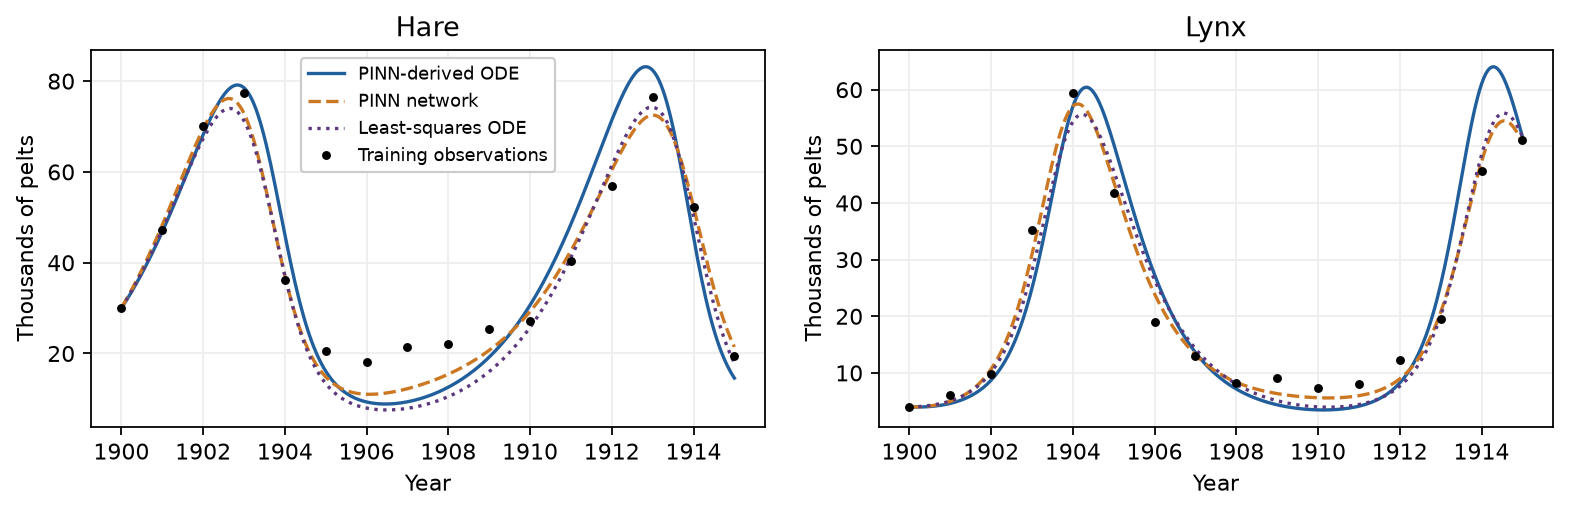

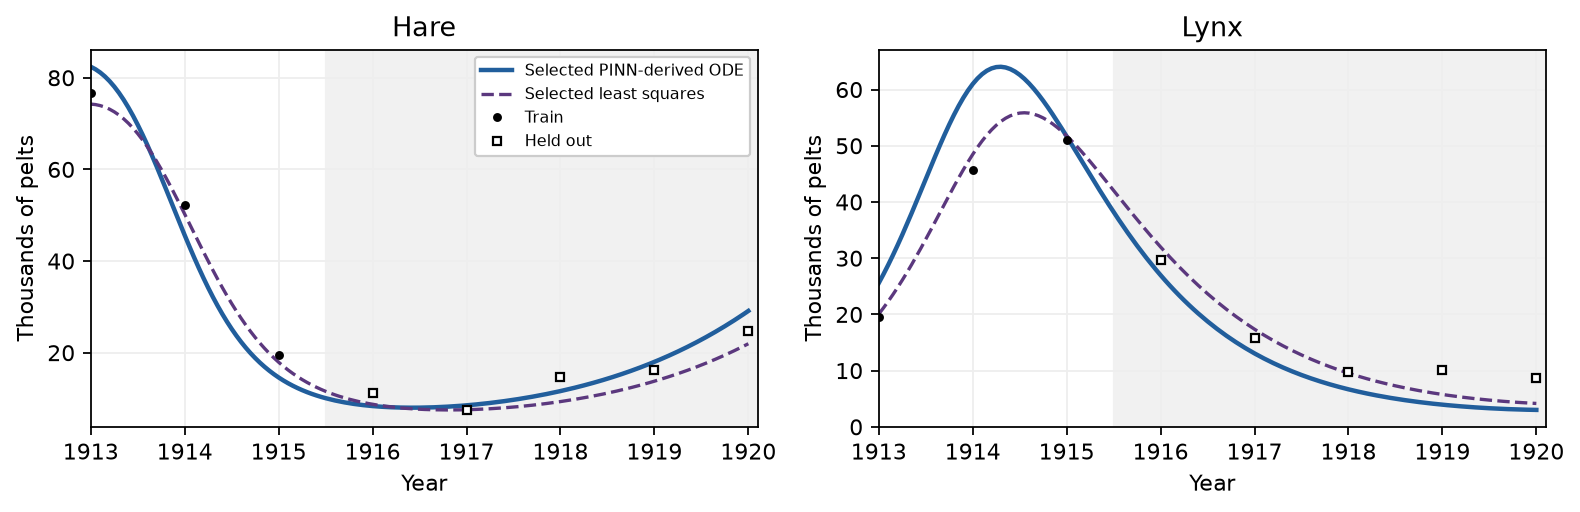

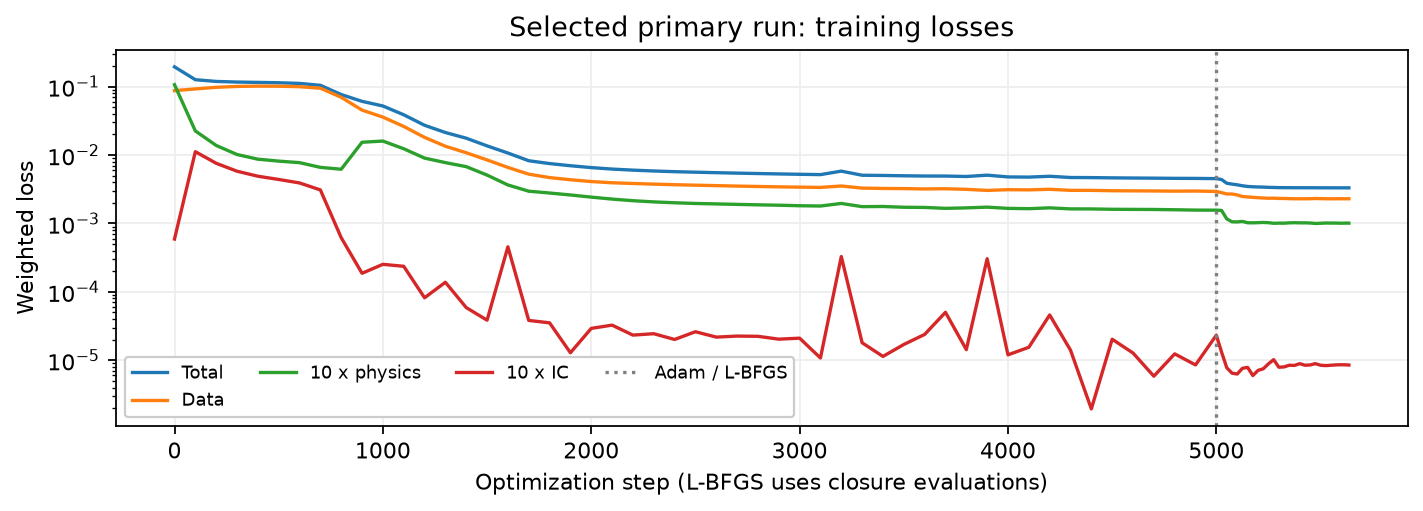

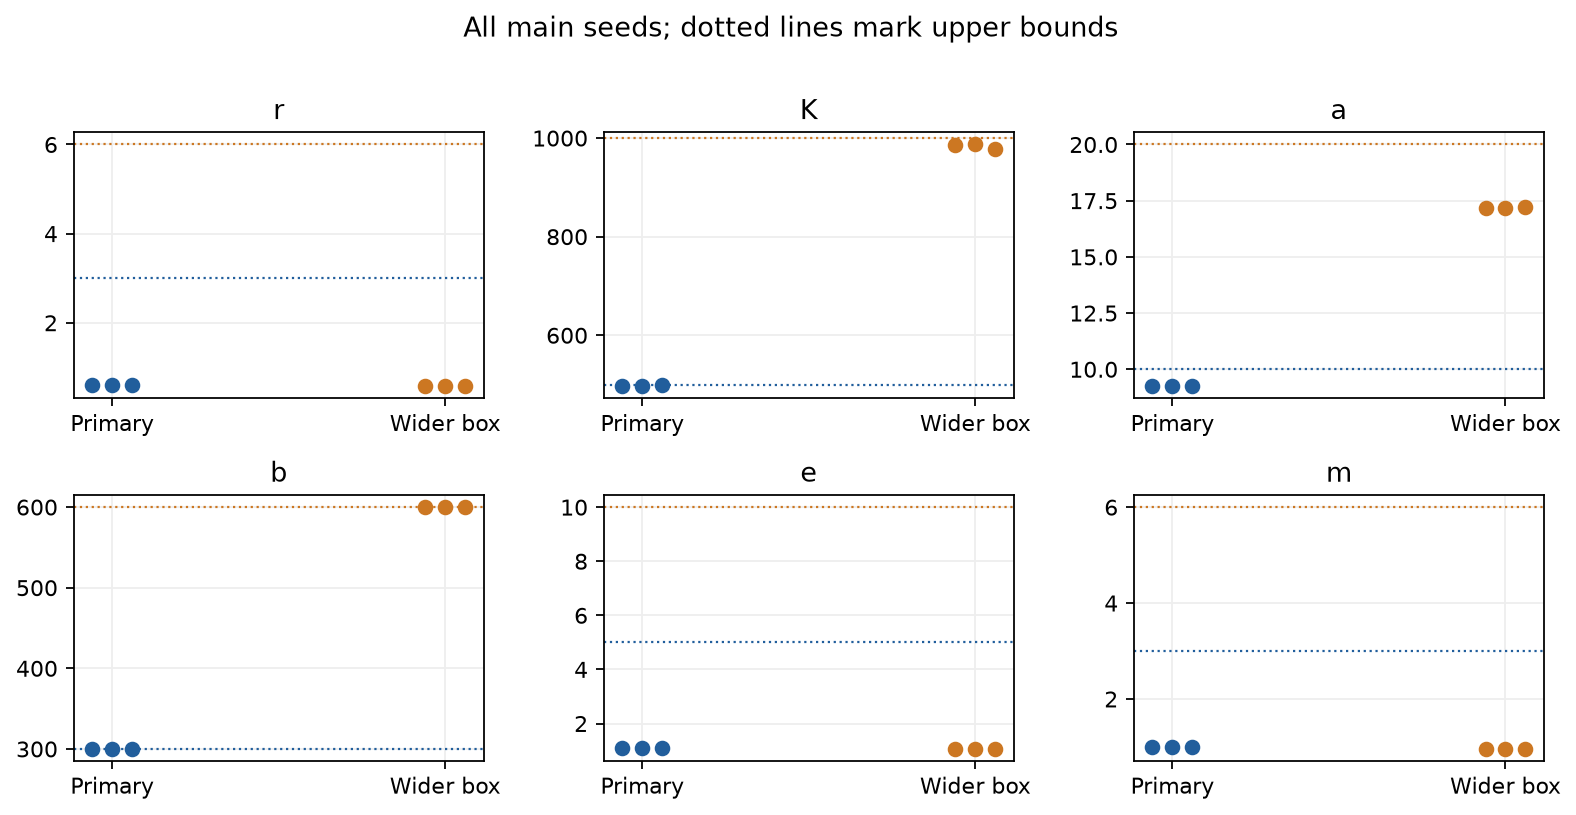

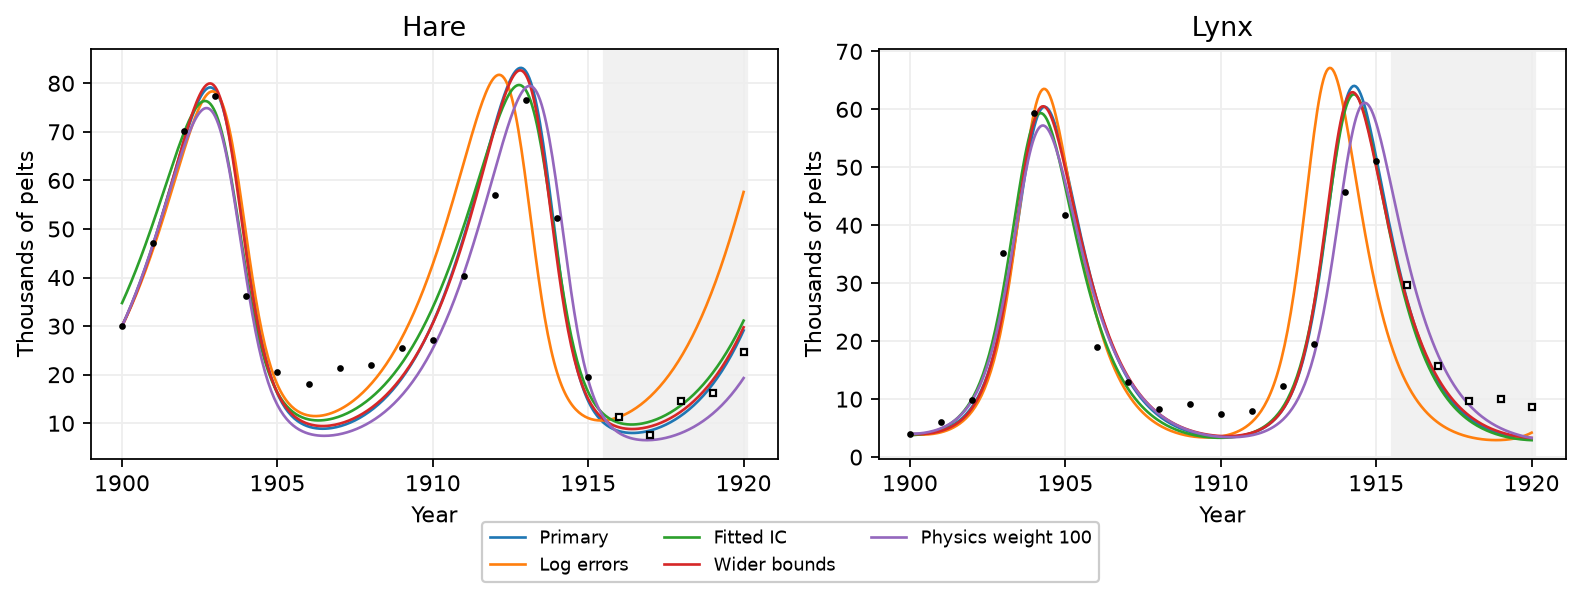

In [29]:
%%team yash
with (BASE/'yash_evaluation_v1/heldout_metrics.csv').open() as f:
    scores=list(csv.DictReader(f))
show_table([{k:r[k] for k in ['case','variant','hare_rmse','lynx_rmse','hare_mae','lynx_mae']} for r in scores if r['selected']=='True'])
receipt=json.loads((BASE/'yash_evaluation_v1/receipt.json').read_text())
assert receipt['test_used_for_model_choices'] is False
assert hashlib.sha256((BASE/'yash_evaluation_v1/heldout_metrics.csv').read_bytes()).hexdigest() == receipt['metrics_sha256']
for stem in ['fit','forecast','loss','bounds','sensitivity']:
    display(Image(filename=str(BASE/f'yash_evaluation_v1/figures/yash_historical_{stem}.png')))

## Batch reproduction
The source modules above contain the complete neural training algorithm. The runner saves each seed's
training history, parameters, initial states, ODE forecasts, network states, residuals and hashes. The
following commands deliberately use **new** directories. Match the runner/scorer directory constants
for a separate reproduction; never overwrite or retune the existing scored iteration.

```text
python scripts/run_historical_pinn.py --config configs/historical.json --output results/historical/reproduction_primary
python scripts/run_historical_pinn.py --config configs/historical_wider_bounds.json --output results/historical/reproduction_wide
python scripts/run_historical_pinn.py --config configs/historical_physics100.json --output results/historical/reproduction_physics100
python scripts/fit_historical_baseline.py --config configs/historical.json --output results/historical/reproduction_baseline
```

Full export, independent baseline, scoring and figure/report-building programs are in `scripts/` in
the same package. `docs/yash_historical_handoff.md` describes the team handoff and interpretation.
The complete dataset, original raw copies and provenance are under `data/historical/`.

---
## Advay: credited contribution
Canonical notebook: `notebooks/advay_data_validation.ipynb`. Cells below execute in the `advay` namespace.

<div style="background:linear-gradient(90deg,#1f5fa8,#1e7a45); padding:18px 22px; border-radius:8px; color:white;">
<h1 style="color:white; margin:0;">Data, Least-Squares Baseline and Validation</h1>
<p style="margin:6px 0 0 0;">MAC F314 Mathematical Modelling &middot; Canadian lynx&ndash;snowshoe hare &middot; Owner: Advay</p>
</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">What this notebook does</b>

1. **Data.** Loads the Hudson's Bay Company pelt counts (1900–1920), checks them and explains what they mean.
2. **Least squares.** Fits the shared Rosenzweig–MacArthur model to 1900–1915 by bounded nonlinear least squares.
3. **Validation.** Scores frozen forecasts from least squares and Yash's PINN on the held-out years 1916–1920.

Every choice that could be influenced by the held-out years was committed to git **before** those years were opened:
`docs/advay_baseline_protocol.md` and `docs/advay_scoring_plan.md`.

</div>

In [30]:
%%team advay
import json, csv, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from lynx_hare.data import read_training
from lynx_hare.model import Parameters, solve
from lynx_hare import historical_ls as hls, stability as st

DATA, RES = ROOT / "data" / "historical", ROOT / "results" / "historical"
config = json.loads((ROOT / "configs" / "historical.json").read_text())
print("Project root:", ROOT)

Project root: C:\Users\Yash\OneDrive\Documents\Study\MM\Project\lynx-hare-project


## 1. The data

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Source and meaning</b>

Annual **thousands of pelts traded** by the Hudson's Bay Company, from the Stan case study (Carpenter, 2018). They are trade counts, **not censuses**.

**Assumption O1:** pelts are proportional to abundance, with unknown constant factors. The model states $H,P$ are defined directly in pelt units:

$$Y_{H,i} = H(t_i) + \varepsilon_{H,i}, \qquad Y_{P,i} = P(t_i) + \varepsilon_{P,i}, \qquad t_i = \text{Year}_i - 1900.$$

So $K,b,a,e$ are *effective* coefficients in pelt units. Only $r$, $m$ and the dimensionless groups have a biological reading.

</div>

In [31]:
%%team advay
split = json.loads((DATA / "split.json").read_text())
train = read_training(DATA / split["train"]["file"], 1900, 1915)   # only the training file
print("Training rows:", len(train.years), " years", int(train.years[0]), "-", int(train.years[-1]))
print("Scale (training maxima):", train.scale, "  initial state:", train.initial_state)
print("Train file sha256 matches split record:",
      __import__("hashlib").sha256((DATA / split["train"]["file"]).read_bytes()).hexdigest() == split["train"]["sha256"])

Training rows:

 16  years 1900 - 1915
Scale (training maxima): [77.4 59.4]   initial state: [30.  4.]
Train file sha256 matches split record: True


### Checks on the training years (from `scripts/advay_data_checks.py`)

Integrity: {'n_rows': 21, 'years': [1900, 1920], 'consecutive_years': True, 'duplicate_years': 0, 'missing_values': 0, 'nonpositive_values': 0}
Hare peaks: [1903, 1913]  Lynx peaks: [1904]
Best lag (lynx after hare): 2 years, r = 0.943
Outliers flagged: [] []


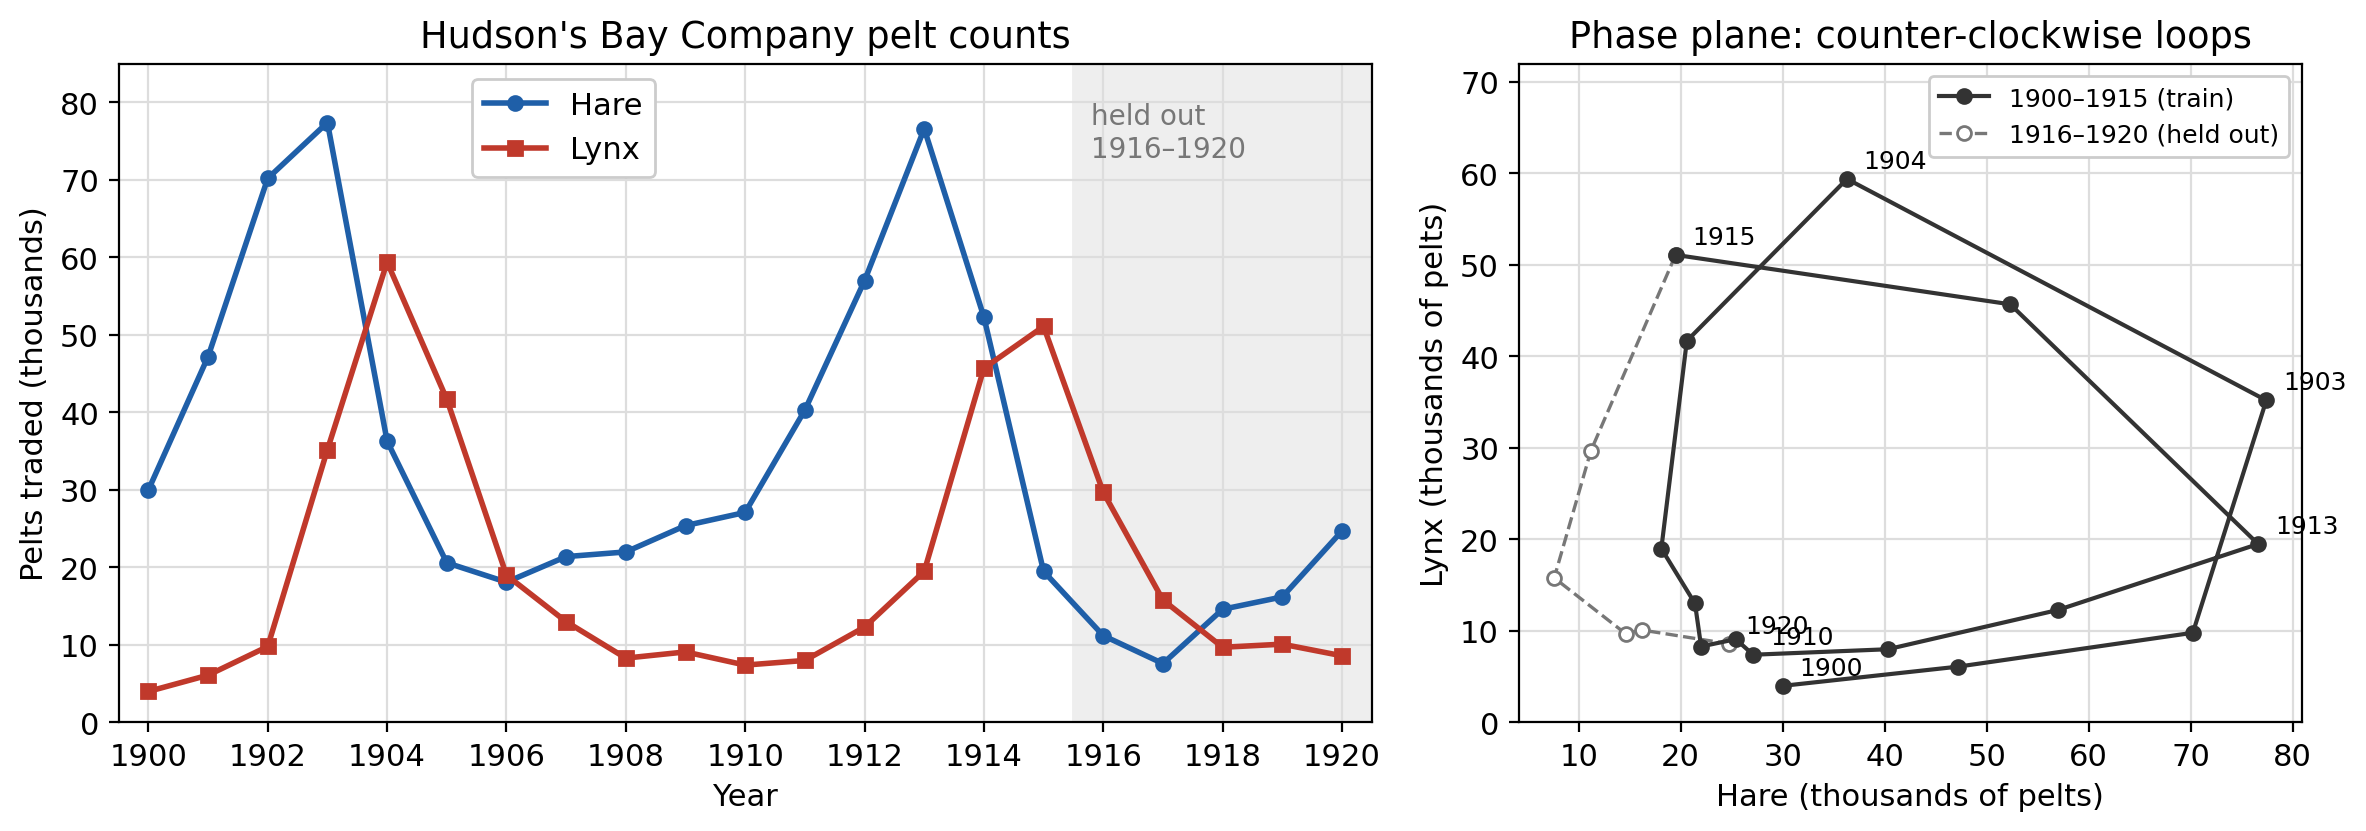

In [32]:
%%team advay
checks = json.loads((RES / "data_checks" / "summary.json").read_text())
t = checks["training"]
print("Integrity:", checks["integrity"])
print("Hare peaks:", t["hare_peaks"], " Lynx peaks:", t["lynx_peaks"])
print("Best lag (lynx after hare):", t["best_lag_years"], "years, r =", t["cross_correlation"][str(t["best_lag_years"])])
print("Outliers flagged:", t["outliers_hare"]["flagged"], t["outliers_lynx"]["flagged"])
display(Image(str(RES / "data_checks" / "figures" / "advay_raw_series.png"), width=900))

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Two compilations disagree</b>

The tsibbledata `pelt` series covers the same records but differs year by year (hare correlation 0.32). All results are conditional on the Stan series.

</div>

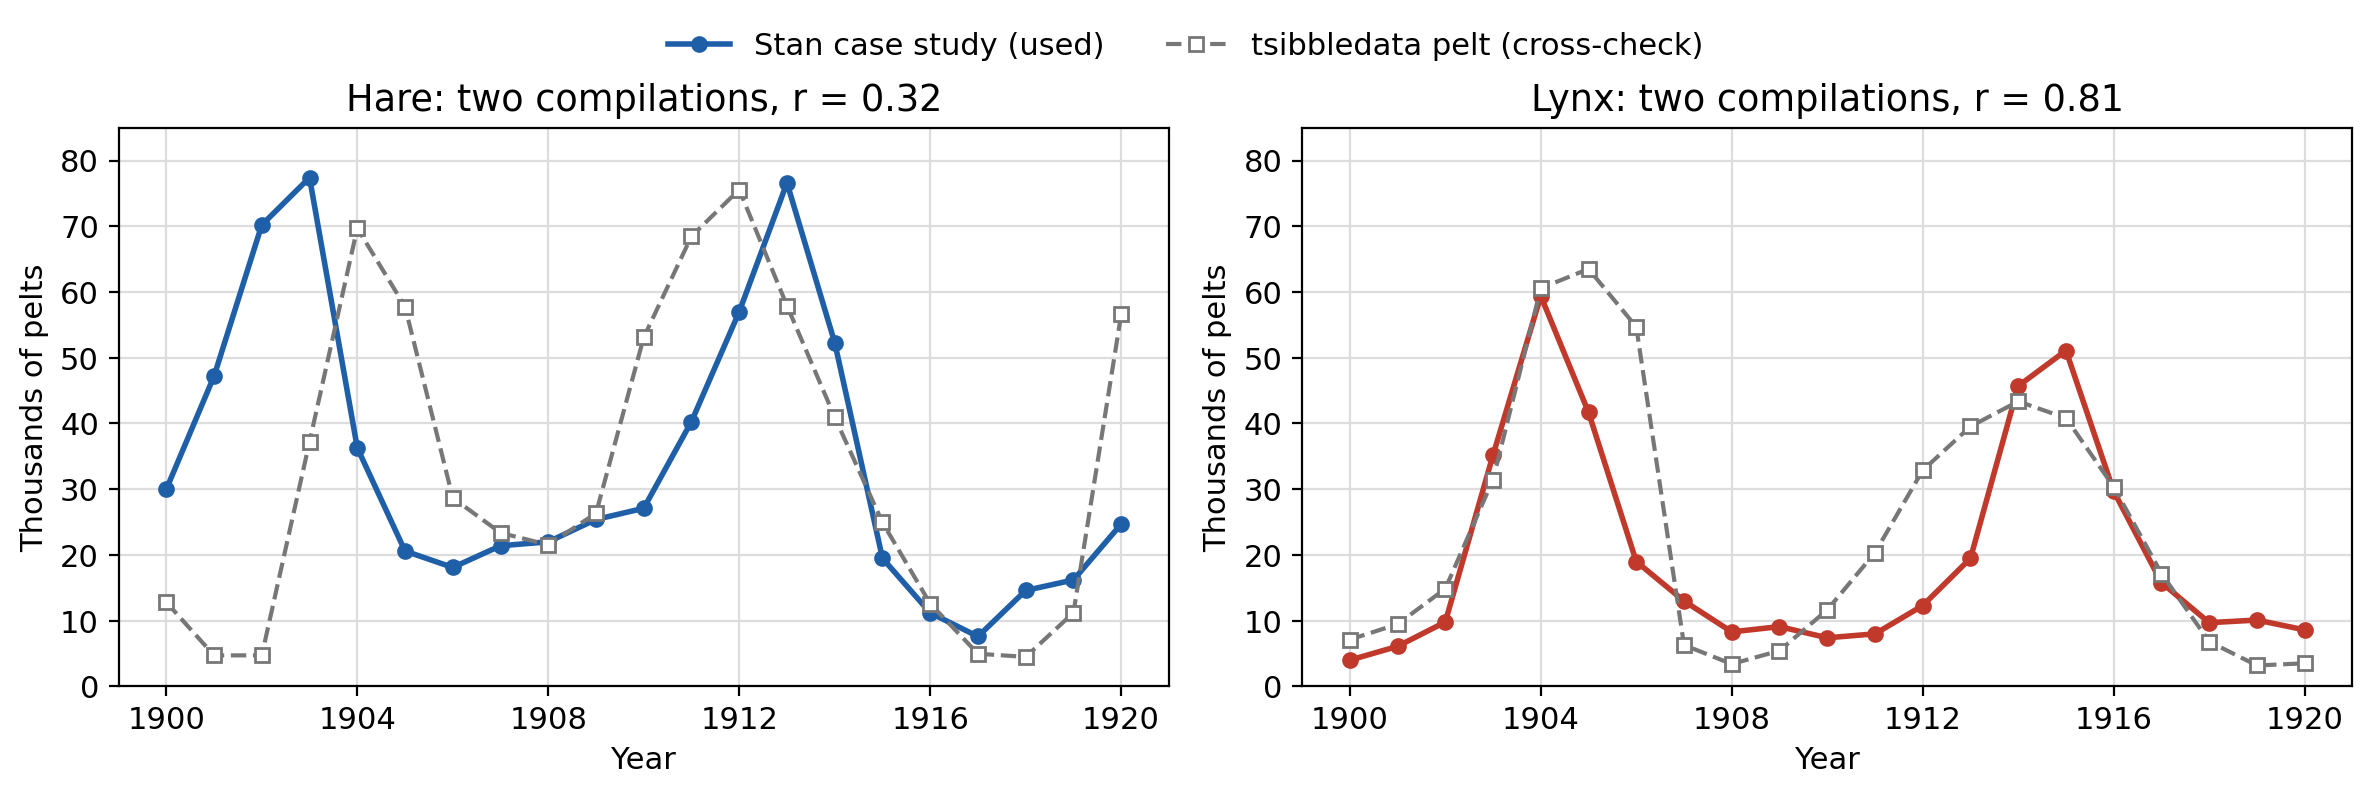

In [33]:
%%team advay
display(Image(str(RES / "data_checks" / "figures" / "advay_source_comparison.png"), width=900))

## 2. Least-squares baseline

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">The fitting problem</b>

With $\\theta=(r,K,a,b,e,m)$, solve

$$\\dot H = rH\\Big(1-\\frac{H}{K}\\Big) - \\frac{aHP}{b+H}, \\qquad \\dot P = \\frac{eaHP}{b+H} - mP$$

from the observed 1900 state with RK45 (rtol $10^{-8}$, atol $10^{-10}$, max step 0.1 yr), and minimise

$$C(\\theta) = \\tfrac12 \\sum_{i=1900}^{1915} \\Big[\\Big(\\tfrac{\\hat H_i - Y_{H,i}}{77.4}\\Big)^2 + \\Big(\\tfrac{\\hat P_i - Y_{P,i}}{59.4}\\Big)^2\\Big]$$

within the shared bounds in `configs/historical.json`.

**Algorithm**
1. Work in $x = \\log\\theta$, because the bounds span up to 600-fold.
2. From each start, run SciPy's bounded trust-region reflective least squares.
3. Use 80 starts per variant: the config guess, 39 Latin-hypercube points uniform in $\\log\\theta$, and 39 uniform in $\\theta$.
4. Keep the lowest training cost.

The two sensitivity variants change one assumption each: log residuals; or fitted $(H_0,P_0)$.

</div>

### Two starts, live: why many starts are needed (the full 240-start run takes about 20 minutes and is loaded below)

In [34]:
%%team advay
problem = hls.Problem(train, config, "main")
settings = {"diff_step": 1e-4, "max_nfev": 2000, "ftol": 1e-10, "xtol": 1e-10, "gtol": 1e-10}
starts = hls.starting_points(problem, 40, 20261027 + 100, "linear")   # v2's ordinary-scale starts (main variant)
for i in (2, 29):
    fit = hls.fit_start(problem, starts[i], settings)
    print(f"start {i:2d}: training cost {fit.cost:.4f}  ",
          {k: round(v, 3) for k, v in problem.unpack(fit.x)[0].to_dict().items()})
print("Start 29 stops in a local minimum about 9x worse than start 2, which reaches the best fit.")

start  2: training cost 0.0845   {'r': 0.647, 'K': 382.426, 'a': 10.0, 'b': 300.0, 'e': 0.967, 'm': 0.857}


start 29: training cost 0.7418   {'r': 2.299, 'K': 83.886, 'a': 2.839, 'b': 20.523, 'e': 1.717, 'm': 3.0}
Start 29 stops in a local minimum about 9x worse than start 2, which reaches the best fit.


variant            cost      r       K      a      b      e      m  sigma  regime  near-best  at bound
main             0.0845  0.647   382.4  10.00  300.0  0.967  0.857  1.067  limit_cycle  18/80  {'a': 'upper', 'b': 'upper'}
log_errors       0.9033  0.520   197.1   7.17  300.0  1.797  1.148  0.550  stable_coexistence  42/78  {'b': 'upper'}
fitted_initial   0.0634  0.520   362.4   8.15  300.0  1.317  1.048  0.993  stable_coexistence  16/80  {'b': 'upper'}


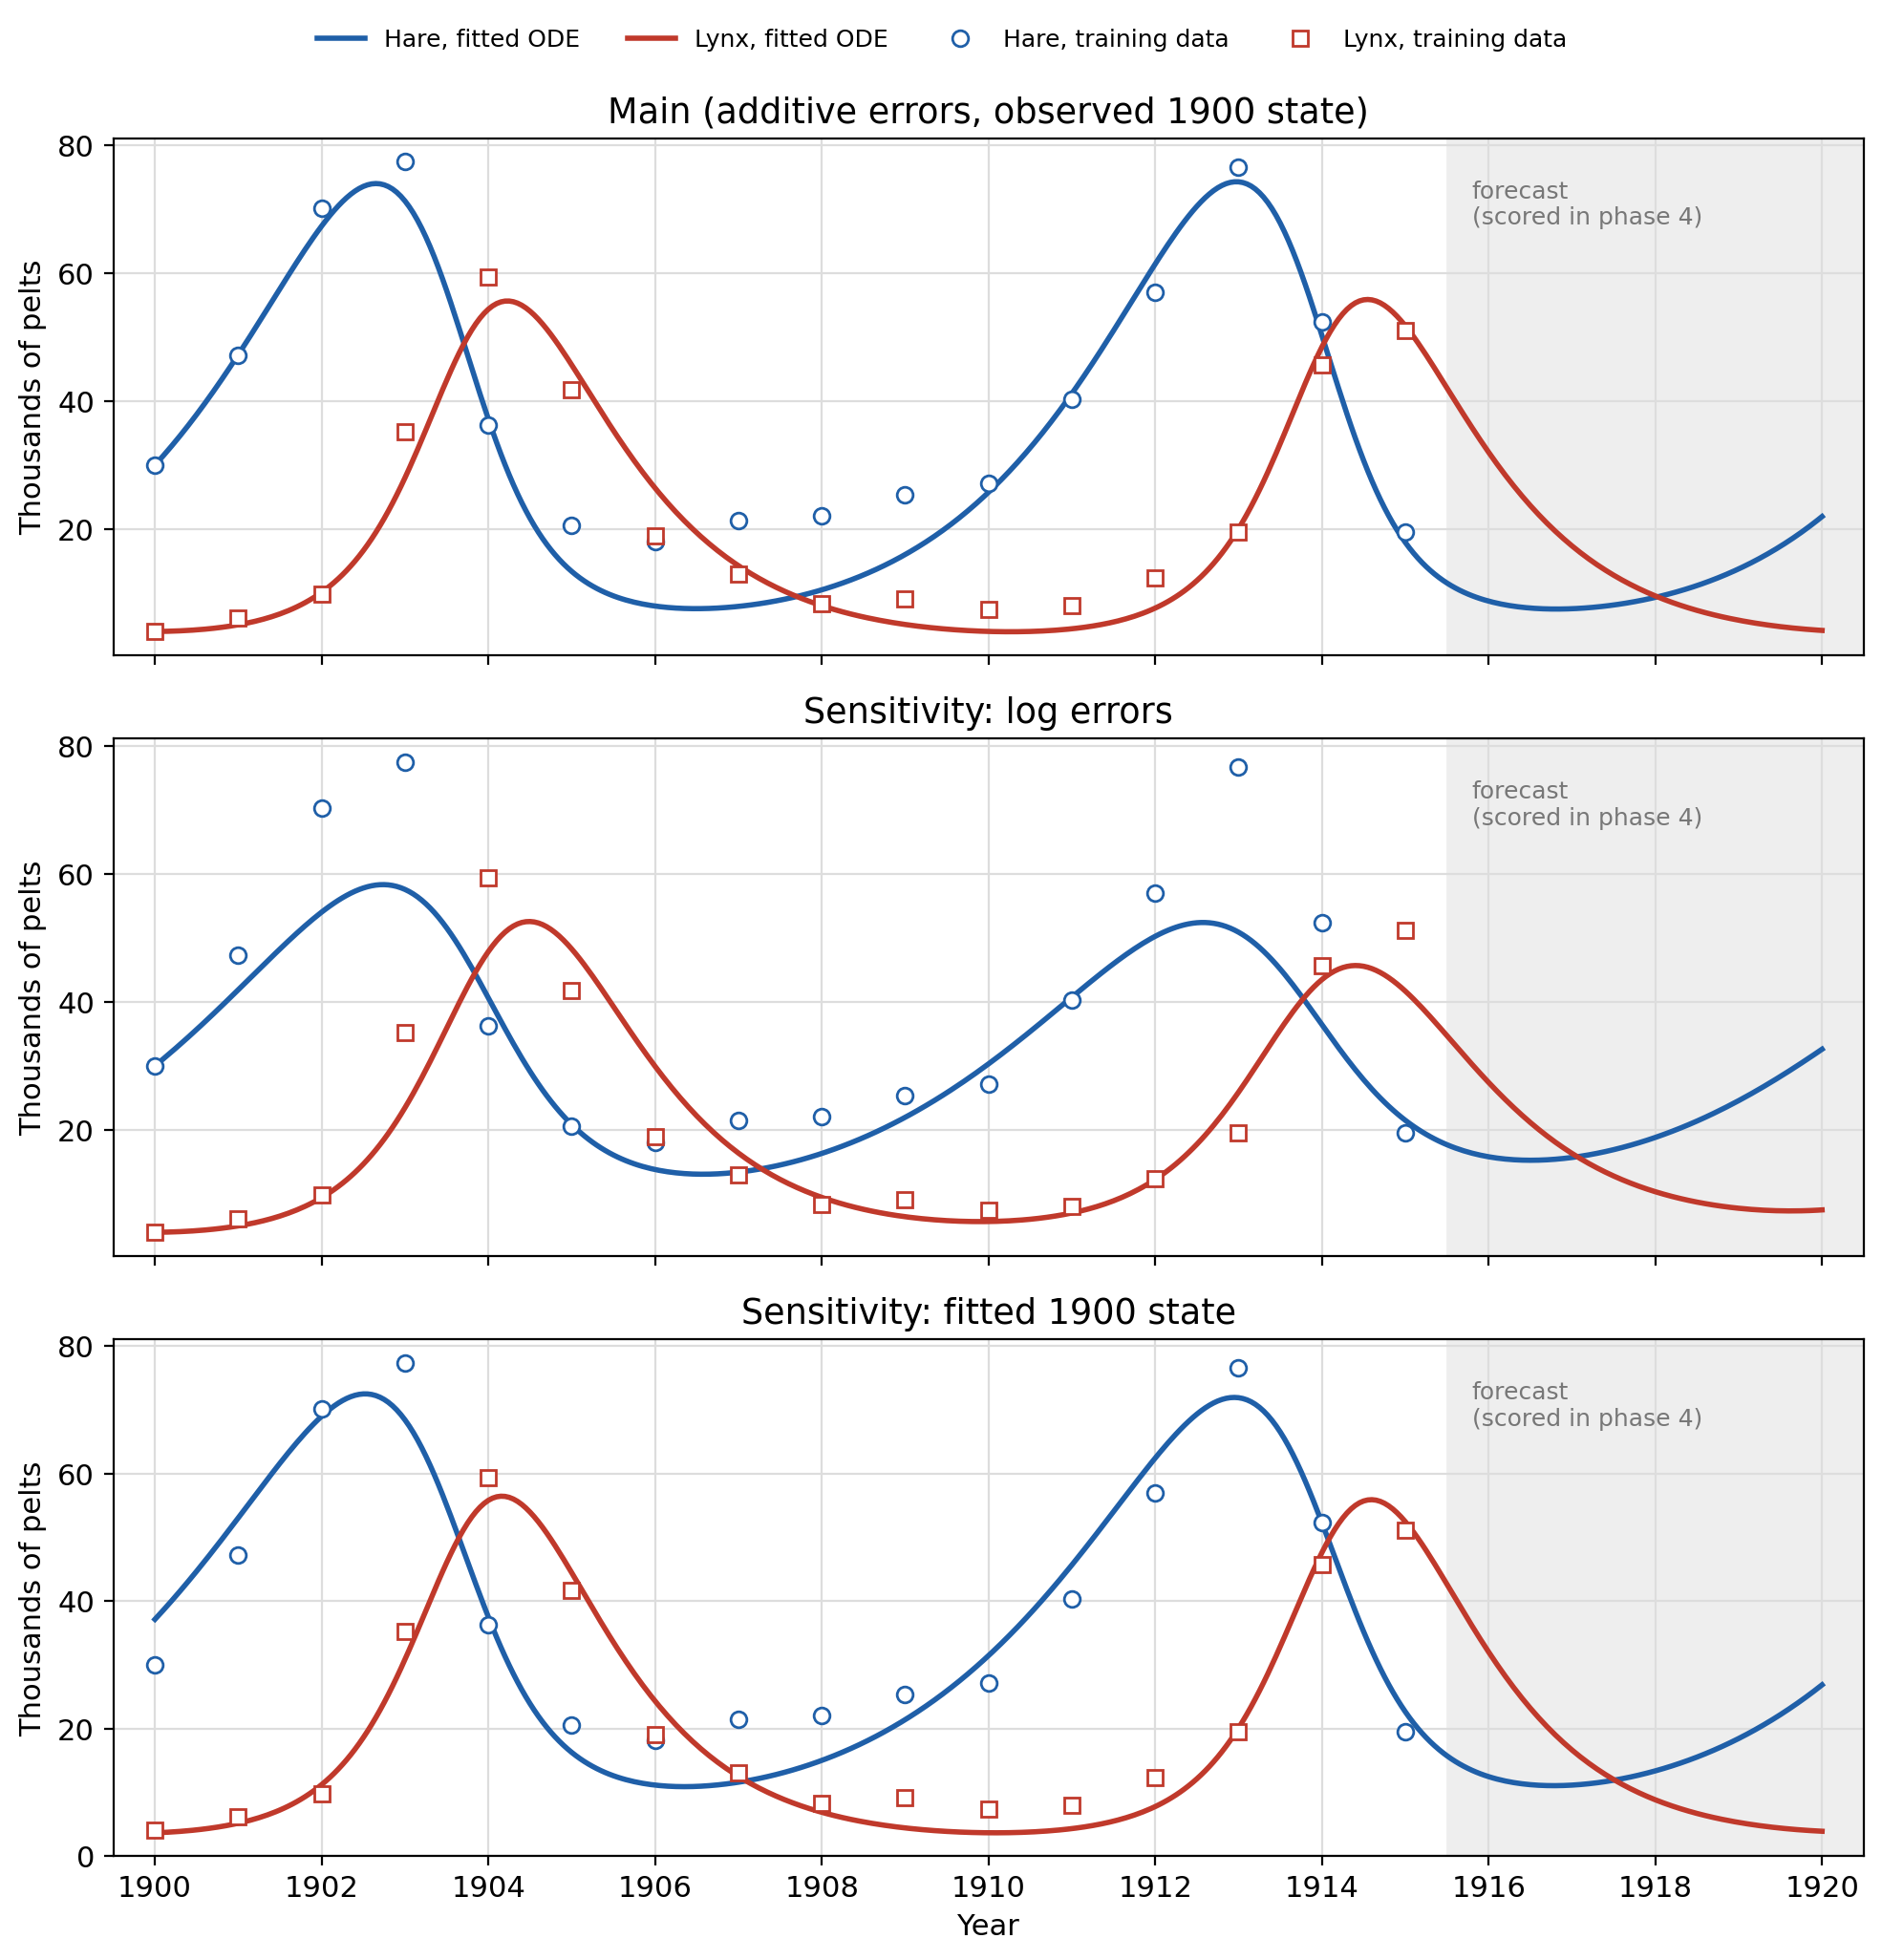

In [35]:
%%team advay
sel = json.loads((RES / "advay_baseline_v2" / "selected.json").read_text())
rows = []
for v, s in sel.items():
    p = s["parameters"]
    rows.append([v, round(s["cost"], 4), *[round(p[k], 3) for k in ("r", "K", "a", "b", "e", "m")],
                 round(s["sigma"], 3), s["regime"], f'{s["starts_near_best"]}/{s["starts_ok"]}', s["at_bound"]])
print(f'{"variant":15s} {"cost":>7s} {"r":>6s} {"K":>7s} {"a":>6s} {"b":>6s} {"e":>6s} {"m":>6s} {"sigma":>6s}  regime  near-best  at bound')
for r in rows:
    print(f"{r[0]:15s} {r[1]:7.4f} {r[2]:6.3f} {r[3]:7.1f} {r[4]:6.2f} {r[5]:6.1f} {r[6]:6.3f} {r[7]:6.3f} {r[8]:6.3f}  {r[9]}  {r[10]}  {r[11]}")
display(Image(str(RES / "advay_baseline_v2" / "figures" / "advay_baseline_fit.png"), width=800))

<div style="background:#fdecea; border-left:6px solid #b03a2e; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b03a2e; font-size:1.1em;">What the fit can and cannot tell us</b>

- **Well defined.** Every start within 1% of the best cost found the same parameters, and Yash's independent least-squares code reaches the same optimum.
- **Saturation not identified.** $b$ hits its upper bound (300 ≫ max hare 77.4), so $aH/(b+H)\\approx (a/b)H$. Only $a/b$ is well determined.
- **Cycle vs damped is undecided.** $\\sigma = K/K_H$ is 1.07, 0.99 or 0.55 depending on the observation assumption, yet all three fit the peak timing.

</div>

Approx. log-parameter standard errors: {'r': 0.2, 'K': 1.09, 'a': 1.18, 'b': 1.38, 'e': 0.15, 'm': 0.1}
Strongest correlations: [(['a', 'b'], 0.998), (['K', 'b'], 0.975), (['K', 'a'], 0.971)]


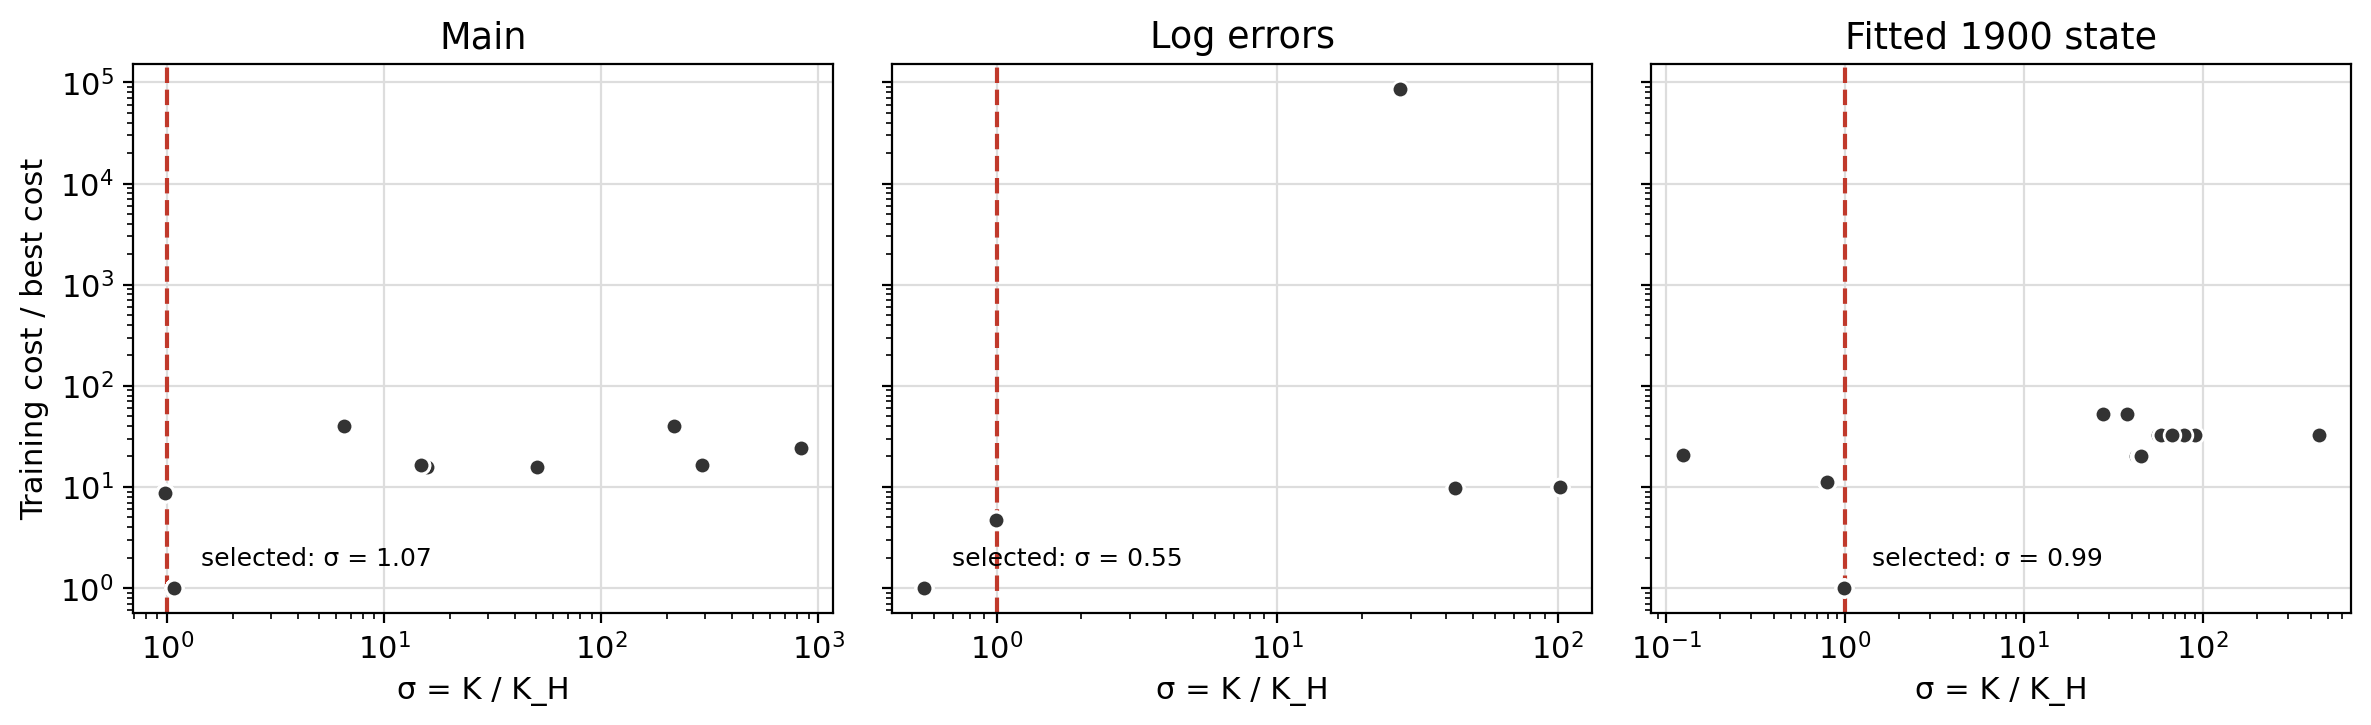

In [36]:
%%team advay
ident = sel["main"]["identifiability"]
print("Approx. log-parameter standard errors:", {k: round(v, 2) for k, v in ident["approx_log_parameter_se"].items()})
print("Strongest correlations:", [(c["pair"], round(c["abs_corr"], 3)) for c in ident["strongest_correlations"][:3]])
display(Image(str(RES / "advay_baseline_v2" / "figures" / "advay_baseline_sigma.png"), width=900))

## 3. Held-out evaluation, 1916–1920

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Scoring rules (declared before opening the test file)</b>

- RMSE and MAE for **each species separately**, in thousands of pelts.
- A method is called **better** only if both of its errors are smaller **and** it is closer in at least 3 of the 5 years; otherwise **similar**.
- Reference forecasts, built from training data only: hold the 1915 value; use the training mean.

</div>

In [37]:
%%team advay
metrics = list(csv.DictReader(open(RES / "advay_evaluation_v1" / "metrics.csv")))
comparison = json.loads((RES / "advay_evaluation_v1" / "comparison.json").read_text())
show = [("LS-Advay", "main"), ("PINN", "main_seed17"), ("Persistence (1915 value)", "-"), ("Training mean", "-")]
for m in metrics:
    if (m["label"], m["run"] if m["label"] == "PINN" else m["variant"]) in show or (m["label"] == "LS-Advay" and m["variant"] == "main"):
        if m["label"] == "PINN" and m["run"] != "main_seed17":
            continue
        print(f'{m["label"]:26s} hare RMSE {float(m["hare_rmse"]):6.2f} MAE {float(m["hare_mae"]):6.2f} | '
              f'lynx RMSE {float(m["lynx_rmse"]):6.2f} MAE {float(m["lynx_mae"]):6.2f}')
for v, c in comparison.items():
    print(f'{v:15s} ({c["status"]}): hare {c["hare_verdict"]}, lynx {c["lynx_verdict"]}')

LS-Advay                   hare RMSE   3.07 MAE   2.59 | lynx RMSE   3.04 MAE   2.56
PINN                       hare RMSE   2.85 MAE   2.59 | lynx RMSE   4.32 MAE   4.05
Persistence (1915 value)   hare RMSE   7.38 MAE   6.72 | lynx RMSE  37.16 MAE  36.32
Training mean              hare RMSE  25.87 MAE  25.23 | lynx RMSE  10.58 MAE  10.21
main            (headline): hare similar, lynx LS better
log_errors      (sensitivity): hare LS better, lynx LS better
fitted_initial  (sensitivity): hare similar, lynx LS better


### Independent recomputation in this notebook

Least squares, main    RMSE hare 3.072 lynx 3.043 | MAE hare 2.587 lynx 2.559
PINN, main seed 17     RMSE hare 2.847 lynx 4.317 | MAE hare 2.590 lynx 4.046


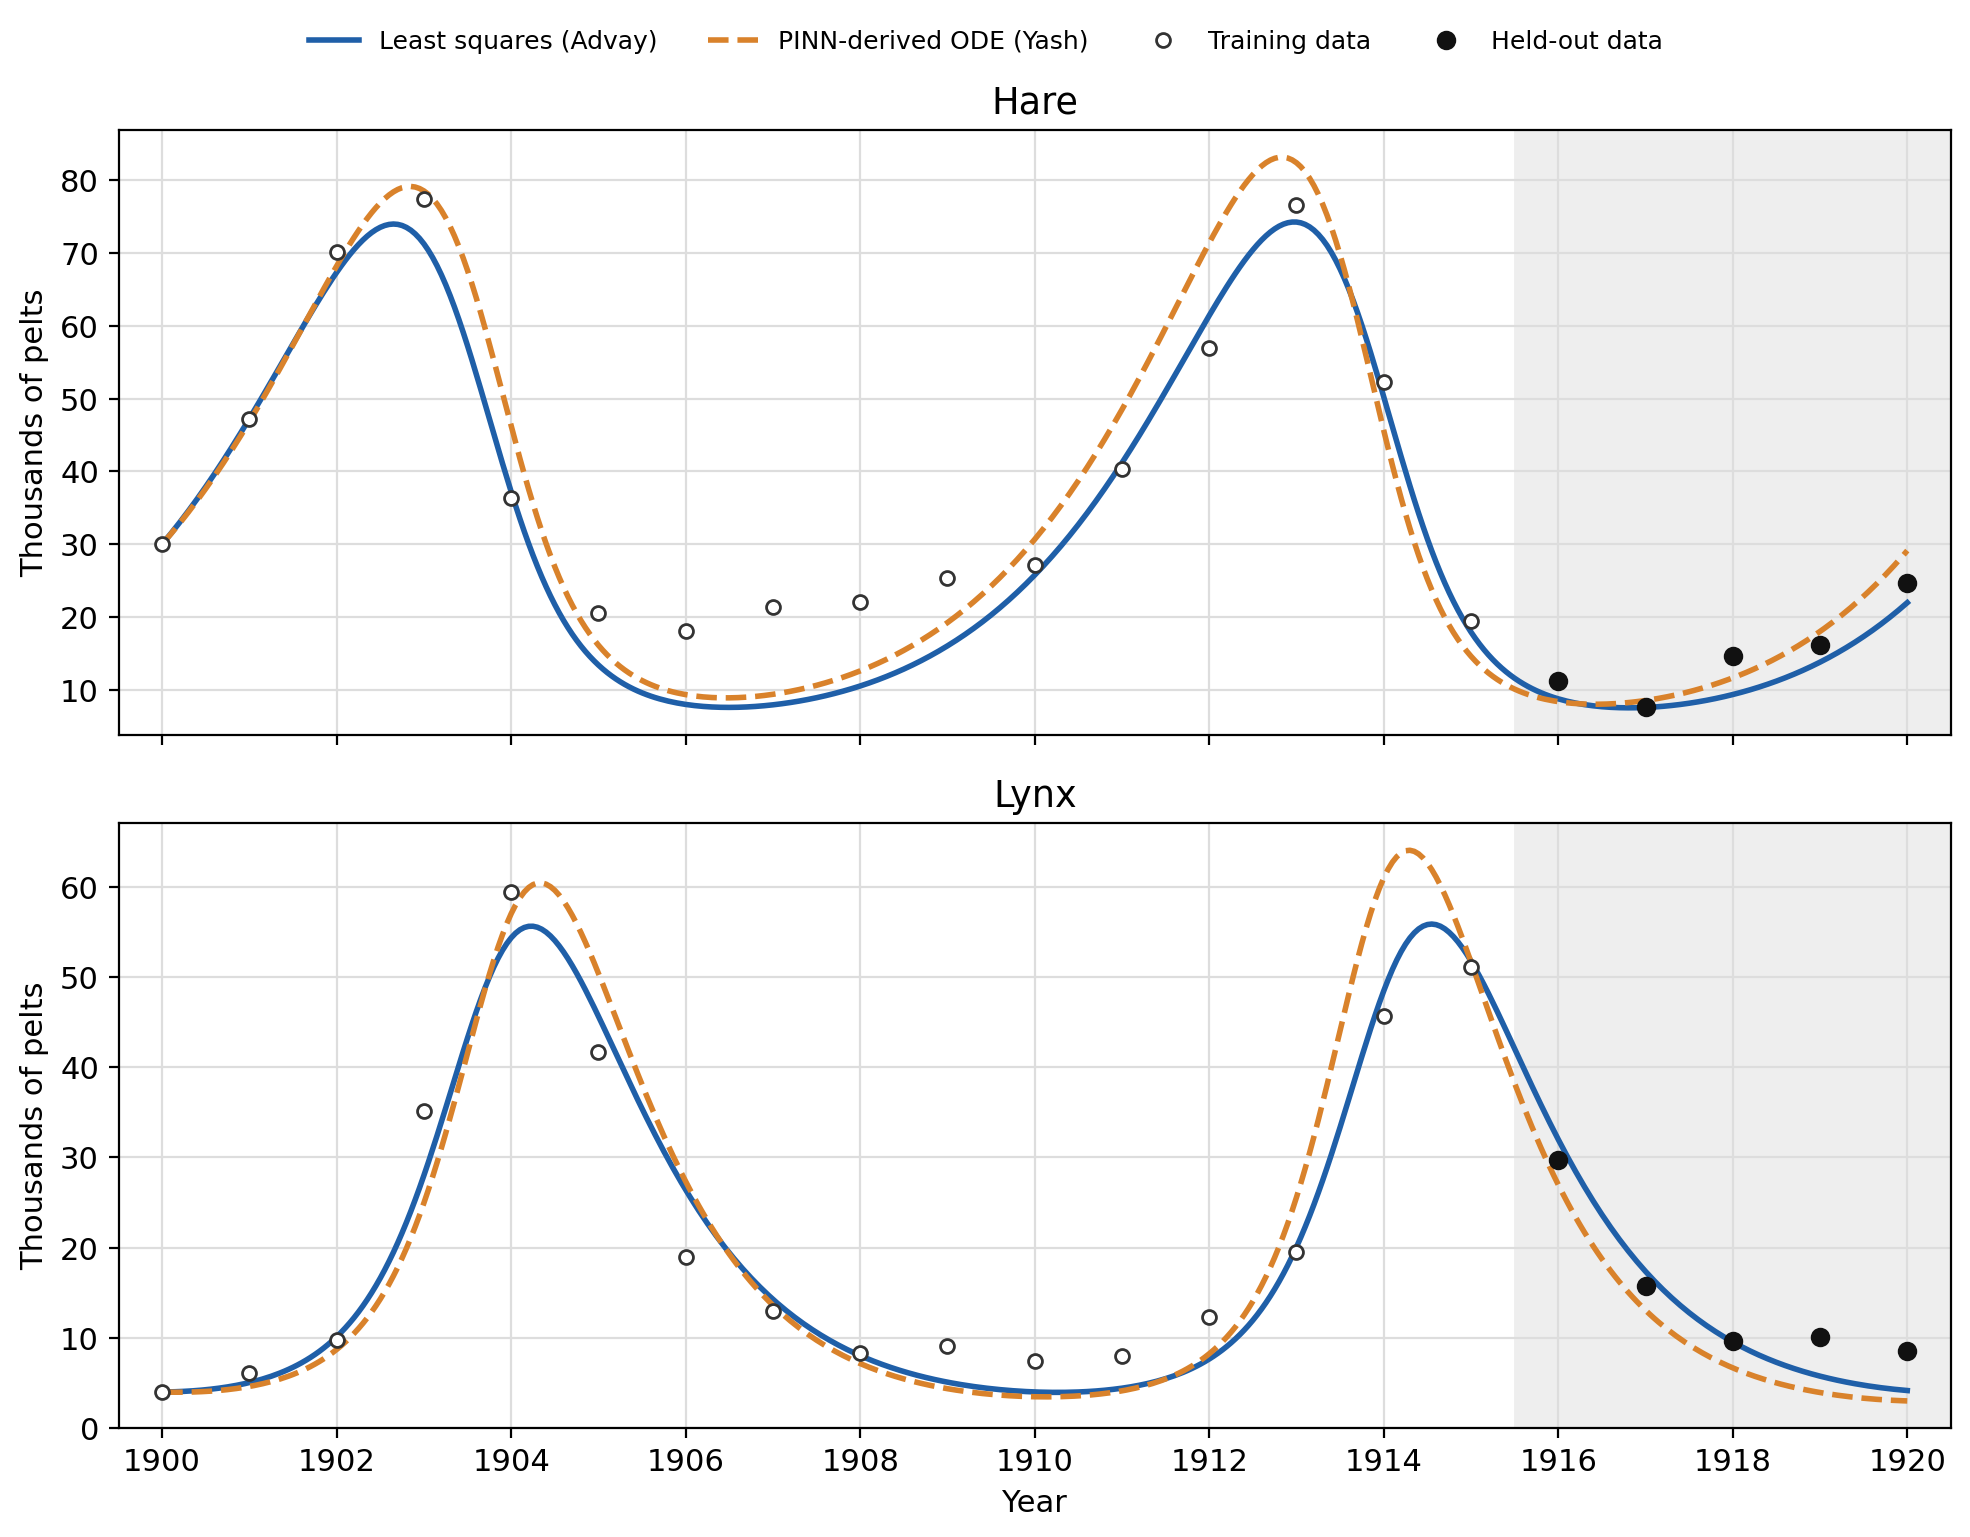

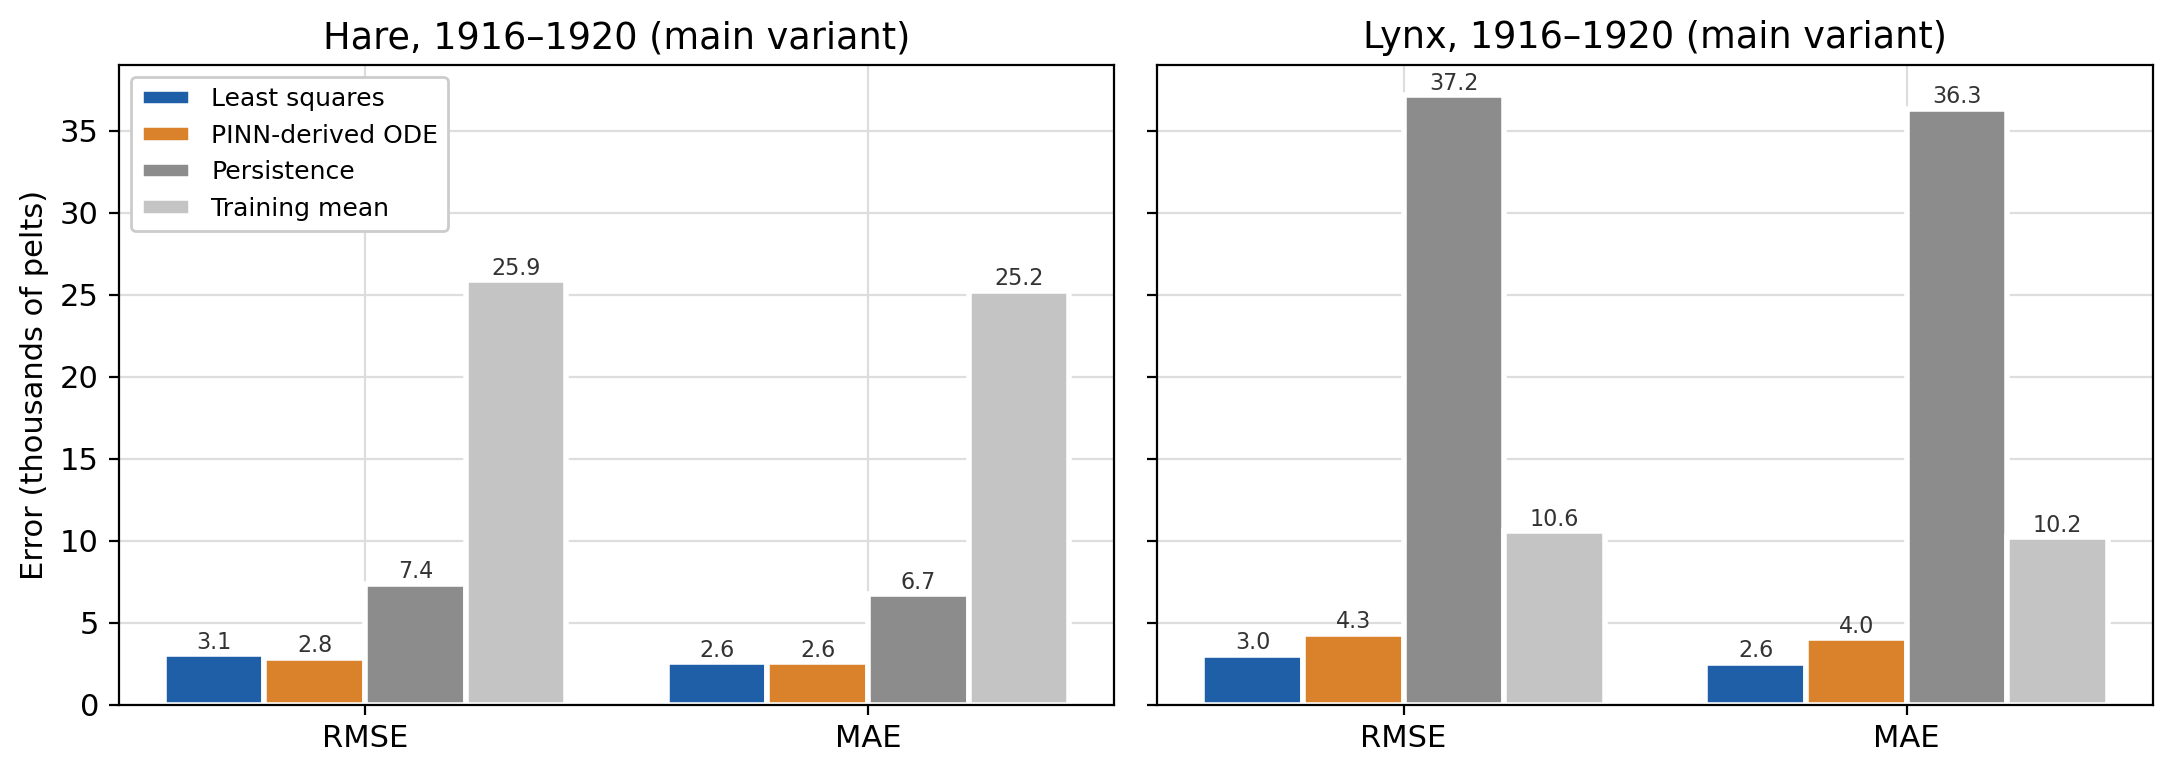

In [38]:
%%team advay
test = np.array([[float(x) for x in r.values()] for r in csv.DictReader(open(DATA / "test_1916_1920.csv"))])
def score(path):
    f = np.array([[float(x) for x in r.values()] for r in csv.DictReader(open(path))])
    d = f[:, 1:] - test[:, 1:]
    return np.sqrt((d**2).mean(0)), np.abs(d).mean(0)
for name, path in [("Least squares, main", RES / "advay_baseline_v2" / "forecast_main.csv"),
                   ("PINN, main seed 17", RES / "yash_pinn_v1" / "runs" / "main_seed17" / "forecast.csv")]:
    rmse, mae = score(path)
    print(f"{name:22s} RMSE hare {rmse[0]:.3f} lynx {rmse[1]:.3f} | MAE hare {mae[0]:.3f} lynx {mae[1]:.3f}")
display(Image(str(RES / "advay_evaluation_v1" / "figures" / "advay_heldout_overlay.png"), width=850))
display(Image(str(RES / "advay_evaluation_v1" / "figures" / "advay_heldout_metrics.png"), width=900))

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Conclusions</b>

- **Both methods forecast the 1916–1920 crash and recovery** to within about 3–4 thousand pelts. Holding the 1915 value gives lynx RMSE 37.
- **Headline:** hare similar; lynx better with least squares (closer in all 5 years).
- **Why they differ:** the PINN's parameters fit the training years 1.9–3.4× worse than the least-squares optimum, and they cycle more strongly (σ ≈ 1.35).
- **Five test points** cannot establish a winner, or whether the real system has a limit cycle.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Limitations</b>

- A 5-point test window starting at the 1915 lynx peak.
- Trade counts rather than censuses, with constant catchability assumed.
- Two source compilations disagree.
- The 1900 observation is treated as exact in the main analysis.
- K, a and b are not identifiable, and b sits on its bound.
- Results are sensitive to the error model.
- The model is a closed two-species system with constant parameters.

</div>

## Synthetic recovery and final verification
The controlled synthetic validation is separate from the historical experiment. These checks reconstruct evidence and scores without fitting or selecting a new model.

In [39]:
%%team verification
import subprocess,sys,csv,json
for script in ['verify_outputs.py','verify_historical_outputs.py']:
    subprocess.run([sys.executable,str(ROOT/'scripts'/script)],cwd=ROOT,check=True)
with (ROOT/'results/synthetic/parameter_recovery.csv').open() as f:
    recovery=list(csv.DictReader(f))
display(recovery[:6])
print('Final evaluation retains all declared sensitivities. Seed spread is not a confidence interval.')


[{'run_id': 'dense_clean_seed17',
  'case': 'dense_clean',
  'seed': '17',
  'variant': 'default',
  'parameter': 'r',
  'estimated': 'True',
  'truth': '1.0',
  'learned': '0.9999429395806201',
  'absolute_relative_error_percent': '0.005706041937991735'},
 {'run_id': 'dense_clean_seed17',
  'case': 'dense_clean',
  'seed': '17',
  'variant': 'default',
  'parameter': 'K',
  'estimated': 'False',
  'truth': '60.0',
  'learned': '60.0',
  'absolute_relative_error_percent': '0.0'},
 {'run_id': 'dense_clean_seed17',
  'case': 'dense_clean',
  'seed': '17',
  'variant': 'default',
  'parameter': 'a',
  'estimated': 'True',
  'truth': '2.0',
  'learned': '1.999971894316394',
  'absolute_relative_error_percent': '0.0014052841803002813'},
 {'run_id': 'dense_clean_seed17',
  'case': 'dense_clean',
  'seed': '17',
  'variant': 'default',
  'parameter': 'b',
  'estimated': 'False',
  'truth': '20.0',
  'learned': '20.0',
  'absolute_relative_error_percent': '0.0'},
 {'run_id': 'dense_clean_seed1

Final evaluation retains all declared sensitivities. Seed spread is not a confidence interval.
